# Phase 7: Regime Validation

**Project:** Regime-Aware Adaptive Trading & Risk Management System (DS605)
**Inputs (read only):** `data/processed/regimes.csv` and `regime_meta.json` (Phase 6), `features.csv`, `returns.csv`, `clean.csv` (Phases 3 and 5)
**Outputs:** tables in `data/processed/regime_*.csv`, figures in `reports/figures/regime_val_*.png`

---

### The question this phase answers

Phase 6 produced three regimes (Calm, Stressed-Decline, Stressed-Rebound) with PCA + K-Means. Clusters always exist, so the real question is: **do they describe distinguishable market conditions, or are they arbitrary slices of a continuum?** Phase 7 tests this from four angles.

| Section | Question | Evidence type |
|---|---|---|
| 7.1 | Do the labels line up with known Indian-market episodes? | Qualitative, historical |
| 7.2 | Do the regimes differ in return, volatility and VIX, and does that hold on data that was **not** a clustering input? | Descriptive + block-bootstrap intervals |
| 7.3 | How persistent are the regimes and how do they switch? | Temporal structure |
| 7.4 (T2) | Would a different training window give the same regimes? | Sensitivity analysis |

### Rules followed

- **Phase 6 is frozen.** Labels, model and k are read from `regimes.csv`. Nothing is re-clustered in 7.1 to 7.3; if a result looks bad, it is reported as bad, not fixed.
- **Trading sessions, not calendar days**, are the unit for transitions and durations. The calendar is the Nifty 50's, set in Phase 1.
- **No look-ahead.** The regime on day *t* is known at the close of *t*. Where this notebook looks forward (e.g. next-day return) it is explicitly to *test* the label, never to define it.
- The T2 check (7.4) fits separate models and is kept apart from the primary results. It does **not** replace `regimes.csv`.
- Seed `42` wherever randomness is used.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)

SEED = 42
TRADING_DAYS = 252
MAX_GAP_DAYS = 7                  # a calendar gap above this between two rows would not be a consecutive session

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG_DIR = ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"regime_val_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Loading and inspecting the Phase 6 and earlier outputs

**What:** load the regime labels and the series they will be validated against, and check that dates, returns and split labels line up.
**Why:** every later number depends on row *t* of `regimes.csv` meaning the same day as row *t* of the other files. A silent misalignment would make a good regime look bad or a bad one look good.
**What is checked:** missing values, duplicate dates, agreement with `features.csv` and `returns.csv`, the train/test boundary, and whether any Nifty trading session is missing between consecutive rows (this matters for transitions and durations).

In [2]:
regimes  = pd.read_csv(PROC / "regimes.csv",  index_col="Date", parse_dates=True)
features = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
returns  = pd.read_csv(PROC / "returns.csv",  index_col="Date", parse_dates=True)
clean    = pd.read_csv(PROC / "clean.csv",    index_col="Date", parse_dates=True)
with open(PROC / "regime_meta.json") as f:
    meta = json.load(f)

REGIME_NAMES = {int(k): v for k, v in meta["regime_names"].items()}
REGIME_IDS = sorted(REGIME_NAMES)
CALM_ID = 0                                           # label order from Phase 6: 0 = lowest mean India VIX in training
COLORS = {0: "#2a9d8f", 1: "#e63946", 2: "#f4a261"}
LABELS = {k: f"{k}: {v}" for k, v in REGIME_NAMES.items()}

reg   = regimes["regime"]
ret   = regimes["nifty_ret_1d"]                       # log return of day t
close = regimes["nifty_close"]
split = regimes["split"]

print("Phase 6 settings   : k =", meta["k"], "| PCA components =", meta["n_components"], "| train_end =", meta["train_end"])
print("Regime names       :", REGIME_NAMES)
print("regimes.csv shape  :", regimes.shape, "|", regimes.index.min().date(), "to", regimes.index.max().date())
print("Missing values     :", int(regimes[["regime", "nifty_ret_1d", "vix_level", "nifty_close"]].isna().sum().sum()))
print("Duplicate dates    :", int(regimes.index.duplicated().sum()), "| sorted:", regimes.index.is_monotonic_increasing)
print("Same dates as features.csv       :", regimes.index.equals(features.index))
print("Max |return diff| vs returns.csv :", float((ret - returns["nifty50"].reindex(regimes.index)).abs().max()))
print("Max |VIX diff|    vs features.csv:", float((regimes["vix_level"] - features["vix_level"]).abs().max()))
print("Split label counts :", split.value_counts().to_dict())
print("Train ends / test starts:", split[split == "train"].index.max().date(), "/", split[split == "test"].index.min().date())

gap_days = regimes.index.to_series().diff().dt.days.dropna()
missing_sessions = clean.index[clean.index >= regimes.index.min()].difference(regimes.index)
print()
print("Calendar gaps between consecutive rows (days):", gap_days.value_counts().sort_index().to_dict())
print("Gaps above", MAX_GAP_DAYS, "days:", int((gap_days > MAX_GAP_DAYS).sum()), "| longest gap:", int(gap_days.max()), "days, ending", gap_days.idxmax().date())
print("Nifty sessions in clean.csv (from the first regime date) that are absent from regimes.csv:", len(missing_sessions))

assert regimes.index.is_unique and regimes.index.is_monotonic_increasing
assert regimes[["regime", "nifty_ret_1d", "vix_level"]].notna().all().all()
assert regimes.index.equals(features.index) and len(missing_sessions) == 0
assert set(reg.unique()) == set(REGIME_IDS) and (gap_days <= MAX_GAP_DAYS).all()

Phase 6 settings   : k = 3 | PCA components = 9 | train_end = 2017-12-31
Regime names       : {0: 'Calm', 1: 'Stressed-Decline', 2: 'Stressed-Rebound'}
regimes.csv shape  : (4509, 17) | 2008-06-09 to 2026-10-27
Missing values     : 0
Duplicate dates    : 0 | sorted: True
Same dates as features.csv       : True
Max |return diff| vs returns.csv : 0.0
Max |VIX diff|    vs features.csv: 0.0
Split label counts : {'train': 2336, 'test': 2173}
Train ends / test starts: 2017-12-29 / 2018-01-02

Calendar gaps between consecutive rows (days): {1.0: 3402, 2.0: 141, 3.0: 842, 4.0: 112, 5.0: 10, 6.0: 1}
Gaps above 7 days: 0 | longest gap: 6 days, ending 2014-10-07
Nifty sessions in clean.csv (from the first regime date) that are absent from regimes.csv: 0


In [3]:
counts = pd.DataFrame({"days": reg.value_counts().sort_index(), "% of all days": (reg.value_counts(normalize=True).sort_index() * 100).round(1)})
counts["train days"] = reg[split == "train"].value_counts().sort_index()
counts["test days"] = reg[split == "test"].value_counts().sort_index()
counts.index = [LABELS[i] for i in counts.index]
display(counts)

,days,% of all days,train days,test days
0: Calm,4040,89.6,1957,2083
1: Stressed-Decline,307,6.8,244,63
2: Stressed-Rebound,162,3.6,135,27


**Interpretation:**
- The files agree exactly: same dates, identical returns, identical VIX, no missing values and no duplicates. There are 4,509 sessions from 2008-06-09 to 2026-10-27.
- **No sessions are missing.** Every Nifty session in `clean.csv` after the first regime date is in `regimes.csv`, and the longest calendar gap between rows is 6 days (ending 2014-10-07), which is a run of exchange holidays and not missing data. So every pair of consecutive rows is a pair of consecutive trading sessions, and the same is true across the train/test boundary (2017-12-29 to 2018-01-02, an ordinary weekend plus New Year's Day). The boundary is therefore **not** treated as a break in 7.3.
- **Coverage limit:** the feature table starts on 2008-06-09 (63-day warm-up, Phase 5), so the first months of 2008 are not covered. This matters for the 2008 event (7.1).
- The regimes are very unevenly sized (Calm is 89.6% of all days). Several results below therefore rest on a few hundred stressed days from a few episodes.

## 3. 7.1 Historical event validation

**What:** for five episodes named in the project outline (2008, 2011, 2013, 2020, 2022), take the already-assigned labels inside the event window and compute the share of days in each regime, the dominant regime, and whether the regime changed during the event.

**Why:** an unsupervised method has no ground truth. If the stressed regimes really capture market stress, they should be common in episodes that practitioners recognise as stressful, and rare in quiet periods. This is a *plausibility* check that costs nothing and is easy to explain in the viva.

**Why these events:** they are the episodes that moved Indian equities or the rupee in this sample. 2008: global credit crisis and heavy foreign selling. 2011: US downgrade and euro-area sovereign stress. 2013: the "taper tantrum", when the rupee fell sharply and the RBI tightened. 2020: Covid crash. 2022: global tightening plus the Russia-Ukraine shock.

**Why distributions and not "one regime per event":** a stress episode is not a block of identical days. It contains relief rallies, quiet days and sharp drops. Even a good regime model should flip during a crisis, so the useful quantity is the *share* of days in each regime and how often it switches. Asking every day to match one label would reject a sensible model.

**Why this is not proof:** the windows are chosen by us with hindsight, the regimes are partly built from volatility and drawdown (which are high in any crisis by definition), and a model could label these episodes correctly while still failing on other dates. Passing this check shows the labels are *not obviously wrong*; it does not show they are right.

**How the windows were defined** (a trigger date to a market low; fixed here, before looking at the labels):

| Event | Window | Rationale |
|---|---|---|
| 2008 GFC | 2008-09-15 to 2009-03-09 | Lehman bankruptcy to the global equity low. (Nifty's first closing low, 2008-10-27, was retested in March 2009, so stopping there would cut the episode short.) Our data starts 2008-06-09. |
| 2011 | 2011-08-01 to 2011-12-20 | US downgrade and euro-area contagion fears to Nifty's closing low for the period (2011-12-20, checked below). |
| 2013 Taper Tantrum | 2013-05-22 to 2013-08-28 | First Fed taper signal to Nifty's closing low for the period (2013-08-28, checked below). |
| 2020 Covid crash | 2020-02-20 to 2020-03-23 | Start of the global selloff to Nifty's closing low (2020-03-23, checked below). |
| 2022 | 2022-01-03 to 2022-06-17 | First session of the year (Fed turning hawkish; Russia invaded Ukraine on 24 Feb; first RBI hike in May) to Nifty's closing low for 2022 (2022-06-17, checked below). Late 2022 is a recovery and is not part of the stress episode. |

**Supplementary windows** are added to test the *rebound* regime and to act as controls. They are reported separately and are not part of the five required rows: the pre-Lehman months of 2008 (data start to 2008-09-12), the 2009 rebound (2009-03-10 to 2009-08-31, *in-sample*), the 2020 rebound (2020-03-24 to 2020-06-30, **out-of-sample**), and two quiet control years, 2017 (in-sample) and 2023 (out-of-sample), which should be mostly Calm.

In [4]:
EVENTS = [
    # (key, label, start, end, role)
    ("gfc",   "2008 Global Financial Crisis", "2008-09-15", "2009-03-09", "required"),
    ("eu",    "2011 Euro sovereign debt crisis", "2011-08-01", "2011-12-20", "required"),
    ("taper", "2013 Taper Tantrum", "2013-05-22", "2013-08-28", "required"),
    ("covid", "2020 Covid-19 crash", "2020-02-20", "2020-03-23", "required"),
    ("y2022", "2022 Inflation, tightening, Ukraine", "2022-01-03", "2022-06-17", "required"),
    ("pre08", "[suppl.] 2008 pre-Lehman (from data start)", "2008-06-09", "2008-09-12", "supplementary"),
    ("reb09", "[suppl.] 2009 rebound (in-sample)", "2009-03-10", "2009-08-31", "supplementary"),
    ("reb20", "[suppl.] 2020 rebound (out-of-sample)", "2020-03-24", "2020-06-30", "supplementary"),
    ("c2017", "[control] 2017 calm year (in-sample)", "2017-01-02", "2017-12-29", "supplementary"),
    ("c2023", "[control] 2023 calm year (out-of-sample)", "2023-01-02", "2023-12-29", "supplementary"),
]

# check the 'closing low' claims made in the window definitions against the data
for key, a, b in [("2011", "2011-07-01", "2011-12-31"), ("2013", "2013-05-01", "2013-10-31"), ("2020", "2020-01-01", "2020-06-30"), ("2022", "2022-01-01", "2022-12-31")]:
    s = close.loc[a:b]
    print(f"Nifty closing low in {key} search window: {s.idxmin().date()} ({s.min():,.0f})")
s = close.loc["2008-09-15":"2009-06-30"]
print(f"Nifty closing low Sep 2008 to Jun 2009: {s.idxmin().date()} ({s.min():,.0f}); close on 2009-03-09: {close.loc['2009-03-09']:,.0f}")

Nifty closing low in 2011 search window: 2011-12-20 (4,544)
Nifty closing low in 2013 search window: 2013-08-28 (5,285)
Nifty closing low in 2020 search window: 2020-03-23 (7,610)
Nifty closing low in 2022 search window: 2022-06-17 (15,294)
Nifty closing low Sep 2008 to Jun 2009: 2008-10-27 (2,524); close on 2009-03-09: 2,573


In [5]:
def event_row(key, label, start, end, role):
    s = reg.loc[start:end]
    share = s.value_counts(normalize=True).reindex(REGIME_IDS, fill_value=0)
    switches = int((s != s.shift()).sum() - 1)
    stressed = s[s != CALM_ID]
    first_stress = stressed.index[0] if len(stressed) else None
    lag = int(s.index.get_loc(first_stress)) if first_stress is not None else np.nan
    move = float(close.loc[first_stress] / close.loc[s.index[0]] - 1) if first_stress is not None else np.nan
    return {
        "key": key, "Historical Event": label, "role": role,
        "Date Range": f"{s.index[0].date()} to {s.index[-1].date()}",
        "Dominant Regime": REGIME_NAMES[int(share.idxmax())],
        "Regime Distribution": " | ".join(f"{REGIME_NAMES[k]} {share[k] * 100:.0f}%" for k in REGIME_IDS),
        "sessions": len(s), "regime switches": switches,
        "regimes visited": int((share > 0).sum()),
        "share Calm %": float(share[0] * 100), "share Decline %": float(share[1] * 100), "share Rebound %": float(share[2] * 100),
        "first non-Calm session (0 = first day)": lag,
        "Nifty move before it fired %": move * 100 if move == move else np.nan,
        "mean India VIX": float(regimes.loc[s.index, "vix_level"].mean()),
        "max India VIX": float(regimes.loc[s.index, "vix_level"].max()),
        "Nifty change over window %": float(close.loc[s.index[-1]] / close.loc[s.index[0]] - 1) * 100,
    }

ev = pd.DataFrame([event_row(*e) for e in EVENTS])

# hand-written reading of each row, filled in after looking at the numbers
EVENT_NOTES = {'gfc': 'Stressed-Decline on 79% of sessions, Stressed-Rebound on 21% (24 sessions of bear-market rallies), never Calm. India VIX averaged 48 and peaked at 85. Fits the profiles from Phase 6, but this window is in the training data, so it is the weakest of the five checks.', 'eu': 'Mixed: 57% Calm, 43% Stressed-Decline, in 7 separate runs (six of 4 to 9 sessions: early Aug, late Aug, late Sep, early Oct, late Nov, mid Dec). 13 switches. India VIX averaged 28 (peak 37). A choppy, moderate stress; the labels flag only its sharpest weeks.', 'taper': 'Mostly Calm (87%). The 9 Stressed-Decline sessions are one 8-session run (19-28 Aug 2013, just before the low) and one isolated day. India VIX averaged 20 (peak 32). First stressed label came 23 sessions in, after Nifty was already 8% down.', 'covid': 'Stressed-Decline on 62% of sessions. The 8 Calm sessions are the first days (20-27 Feb) plus 3 in early March. The label first fired on 28 Feb after Nifty had fallen 7%, then stayed stressed through the trough (6-23 Mar, Nifty -31% inside that run). Out-of-sample, and the clearest pass.', 'y2022': 'Mostly Calm (86%). India VIX averaged 21 (peak 32). Stressed-Decline appears in short runs (6 sessions from 2 Mar, then scattered), 14 switches. Nifty fell 13% peak-to-trough, but at moderate volatility, so the labels do not mark H1 2022 as a stress regime.', 'pre08': 'Stressed-Decline 66%, Stressed-Rebound 22%, Calm 12%: already stressed before Lehman (India VIX averaged 35 and peaked at 62 from the data start in June 2008).', 'reb09': 'In-sample: 82% Stressed-Rebound. The cluster was built from exactly these days, so this is expected and is not independent evidence.', 'reb20': 'Out-of-sample: Stressed-Rebound is the most common label but only 42%; 34% Stressed-Decline and 25% Calm, with 12 switches. The Rebound label generalises only partially.', 'c2017': '100% Calm, zero switches (India VIX averaged 12.6). Control passed (in-sample).', 'c2023': '100% Calm, zero switches (India VIX averaged 12.4). Control passed (out-of-sample).'}
ev["Interpretation"] = ev["key"].map(EVENT_NOTES)

req_cols = ["Historical Event", "Date Range", "Dominant Regime", "Regime Distribution", "Interpretation"]
print("REQUIRED EVENTS")
display(ev[ev["role"] == "required"][req_cols].set_index("Historical Event"))

REQUIRED EVENTS


,Date Range,Dominant Regime,Regime Distribution,Interpretation
Historical Event,,,,
2008 Global Financial Crisis,2008-09-15 to 2009-03-09,Stressed-Decline,Calm 0% | Stressed-Decline 79% | Stressed-Rebound 21%,"Stressed-Decline on 79% of sessions, Stressed-Rebound on 21% (24 sessions of bear-market rallies), never Calm. India VIX averaged 48 and peaked at 85. Fits the profiles from Phase 6, but this wind..."
2011 Euro sovereign debt crisis,2011-08-01 to 2011-12-20,Calm,Calm 57% | Stressed-Decline 43% | Stressed-Rebound 0%,"Mixed: 57% Calm, 43% Stressed-Decline, in 7 separate runs (six of 4 to 9 sessions: early Aug, late Aug, late Sep, early Oct, late Nov, mid Dec). 13 switches. India VIX averaged 28 (peak 37). A cho..."
2013 Taper Tantrum,2013-05-22 to 2013-08-28,Calm,Calm 87% | Stressed-Decline 13% | Stressed-Rebound 0%,"Mostly Calm (87%). The 9 Stressed-Decline sessions are one 8-session run (19-28 Aug 2013, just before the low) and one isolated day. India VIX averaged 20 (peak 32). First stressed label came 23 s..."
2020 Covid-19 crash,2020-02-20 to 2020-03-23,Stressed-Decline,Calm 38% | Stressed-Decline 62% | Stressed-Rebound 0%,"Stressed-Decline on 62% of sessions. The 8 Calm sessions are the first days (20-27 Feb) plus 3 in early March. The label first fired on 28 Feb after Nifty had fallen 7%, then stayed stressed throu..."
"2022 Inflation, tightening, Ukraine",2022-01-03 to 2022-06-17,Calm,Calm 86% | Stressed-Decline 14% | Stressed-Rebound 0%,"Mostly Calm (86%). India VIX averaged 21 (peak 32). Stressed-Decline appears in short runs (6 sessions from 2 Mar, then scattered), 14 switches. Nifty fell 13% peak-to-trough, but at moderate vola..."


In [6]:
ctx_cols = ["Historical Event", "sessions", "regime switches", "regimes visited", "first non-Calm session (0 = first day)",
            "Nifty move before it fired %", "mean India VIX", "max India VIX", "Nifty change over window %"]
print("CONTEXT FOR THE SAME WINDOWS (required rows first, then supplementary)")
display(ev[ctx_cols].set_index("Historical Event").round(1))

print("SUPPLEMENTARY WINDOWS (rebound tests and calm controls)")
display(ev[ev["role"] == "supplementary"][req_cols].set_index("Historical Event"))

# robustness of the window definitions: the same five events as full calendar years
cal = []
for key, label, a, b in [("2008", "2008 (data start to 31 Dec)", "2008-06-09", "2008-12-31"), ("2011", "Calendar 2011", "2011-01-01", "2011-12-31"),
                         ("2013", "Calendar 2013", "2013-01-01", "2013-12-31"), ("2020", "Calendar 2020", "2020-01-01", "2020-12-31"),
                         ("2022", "Calendar 2022", "2022-01-01", "2022-12-31")]:
    s = reg.loc[a:b]; sh = s.value_counts(normalize=True).reindex(REGIME_IDS, fill_value=0) * 100
    cal.append({"Window": label, "sessions": len(s), "Calm %": sh[0], "Stressed-Decline %": sh[1], "Stressed-Rebound %": sh[2]})
print("SENSITIVITY: the same events defined as full calendar years")
display(pd.DataFrame(cal).set_index("Window").round(0))

CONTEXT FOR THE SAME WINDOWS (required rows first, then supplementary)


,sessions,regime switches,regimes visited,first non-Calm session (0 = first day),Nifty move before it fired %,mean India VIX,max India VIX,Nifty change over window %
Historical Event,,,,,,,,
2008 Global Financial Crisis,114,8,2,0.0,0.0,48.0,85.1,-36.8
2011 Euro sovereign debt crisis,92,13,2,4.0,-5.5,27.8,37.2,-17.6
2013 Taper Tantrum,69,3,2,23.0,-8.3,19.8,32.4,-13.3
2020 Covid-19 crash,21,3,2,5.0,-7.3,37.2,72.2,-37.0
"2022 Inflation, tightening, Ukraine",114,14,2,37.0,-7.8,21.4,32.0,-13.2
[suppl.] 2008 pre-Lehman (from data start),68,9,3,0.0,0.0,35.1,61.7,-6.1
[suppl.] 2009 rebound (in-sample),117,9,3,0.0,0.0,42.8,62.0,78.1
[suppl.] 2020 rebound (out-of-sample),65,12,3,0.0,0.0,40.3,83.6,32.1
[control] 2017 calm year (in-sample),248,0,1,NaN,NaN,12.6,16.8,28.7


SUPPLEMENTARY WINDOWS (rebound tests and calm controls)


,Date Range,Dominant Regime,Regime Distribution,Interpretation
Historical Event,,,,
[suppl.] 2008 pre-Lehman (from data start),2008-06-09 to 2008-09-12,Stressed-Decline,Calm 12% | Stressed-Decline 66% | Stressed-Rebound 22%,"Stressed-Decline 66%, Stressed-Rebound 22%, Calm 12%: already stressed before Lehman (India VIX averaged 35 and peaked at 62 from the data start in June 2008)."
[suppl.] 2009 rebound (in-sample),2009-03-12 to 2009-08-31,Stressed-Rebound,Calm 5% | Stressed-Decline 13% | Stressed-Rebound 82%,"In-sample: 82% Stressed-Rebound. The cluster was built from exactly these days, so this is expected and is not independent evidence."
[suppl.] 2020 rebound (out-of-sample),2020-03-24 to 2020-06-30,Stressed-Rebound,Calm 25% | Stressed-Decline 34% | Stressed-Rebound 42%,"Out-of-sample: Stressed-Rebound is the most common label but only 42%; 34% Stressed-Decline and 25% Calm, with 12 switches. The Rebound label generalises only partially."
[control] 2017 calm year (in-sample),2017-01-02 to 2017-12-29,Calm,Calm 100% | Stressed-Decline 0% | Stressed-Rebound 0%,"100% Calm, zero switches (India VIX averaged 12.6). Control passed (in-sample)."
[control] 2023 calm year (out-of-sample),2023-01-02 to 2023-12-29,Calm,Calm 100% | Stressed-Decline 0% | Stressed-Rebound 0%,"100% Calm, zero switches (India VIX averaged 12.4). Control passed (out-of-sample)."


SENSITIVITY: the same events defined as full calendar years


,sessions,Calm %,Stressed-Decline %,Stressed-Rebound %
Window,,,,
2008 (data start to 31 Dec),138,6.0,75.0,19.0
Calendar 2011,242,83.0,17.0,0.0
Calendar 2013,247,94.0,6.0,0.0
Calendar 2020,250,75.0,14.0,11.0
Calendar 2022,248,94.0,6.0,0.0


In [6]:
# Where inside each required window do the stressed labels fall? (runs of consecutive non-Calm sessions)
rows = []
for key, label, a, b, role in EVENTS:
    if role != "required":
        continue
    s = reg.loc[a:b]; stressed = (s != CALM_ID).to_numpy()
    run = np.r_[0, np.cumsum(stressed[1:] != stressed[:-1])]
    for r_id in np.unique(run[stressed]):
        seg = s.index[(run == r_id) & stressed]
        mix = s.loc[seg].value_counts()
        rows.append({"event": label.split(" ")[0] + (" GFC" if key == "gfc" else ""), "stressed run": f"{seg[0].date()} to {seg[-1].date()}", "sessions": len(seg),
                     "regimes": ", ".join(f"{REGIME_NAMES[int(k)]} {v}" for k, v in mix.items()),
                     "Nifty change over run %": round(float(close.loc[seg[-1]] / close.loc[seg[0]] - 1) * 100, 1)})
runs_df = pd.DataFrame(rows)
print("Runs of consecutive stressed-regime sessions inside the required windows (runs of 3+ sessions)")
display(runs_df[runs_df["sessions"] >= 3].set_index(["event", "stressed run"]))
print("Number of stressed runs per window (all lengths):", runs_df.groupby("event").size().to_dict())

Runs of consecutive stressed-regime sessions inside the required windows (runs of 3+ sessions)


sessions                                   regimes  Nifty change over run %
event    stressed run                                                                                         
2008 GFC 2008-09-15 to 2009-03-09       114  Stressed-Decline 90, Stressed-Rebound 24                    -36.8
2011     2011-08-05 to 2011-08-16         7                        Stressed-Decline 7                     -3.4
         2011-08-18 to 2011-08-30         9                        Stressed-Decline 9                      1.1
         2011-09-22 to 2011-09-28         5                        Stressed-Decline 5                      0.5
         2011-09-30 to 2011-10-10         6                        Stressed-Decline 6                      0.7
         2011-11-23 to 2011-11-29         4                        Stressed-Decline 4                      2.1
         2011-12-09 to 2011-12-20         8                        Stressed-Decline 8                     -6.6
2013     2013-08-19 to 2013-08-28         8                        Stressed-Decline 8                     -2.4
2020     2020-03-06 to 2020-03-23        11                       Stressed-Decline 11                    -30.7
2022     2022-03-02 to 2022-03-09         6                        Stressed-Decline 6                     -1.6

Number of stressed runs per window (all lengths): {'2008 GFC': 1, '2011': 7, '2013': 2, '2020': 2, '2022': 7}


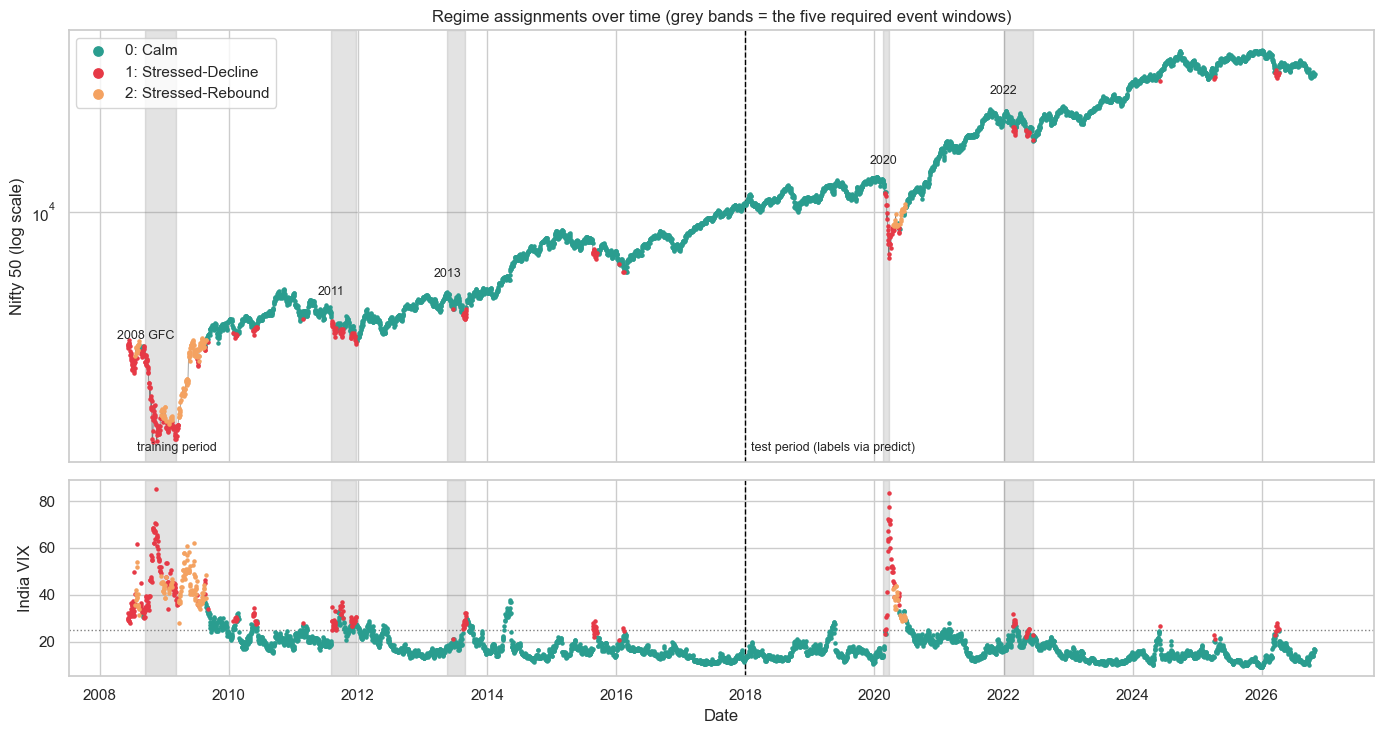

In [7]:
# Figure 1: full timeline with event windows highlighted (top: Nifty, bottom: India VIX)
fig, ax = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for k in REGIME_IDS:
    m = reg == k
    ax[0].scatter(close.index[m], close[m], s=5, color=COLORS[k], label=LABELS[k], zorder=3)
    ax[1].scatter(regimes.index[m], regimes["vix_level"][m], s=5, color=COLORS[k], zorder=3)
ax[0].plot(close.index, close, color="black", lw=.5, alpha=.5, zorder=2)
ax[0].set_yscale("log"); ax[0].set_ylabel("Nifty 50 (log scale)")
ax[1].set_ylabel("India VIX"); ax[1].axhline(25, ls=":", color="grey", lw=1)
for key, label, a, b, role in EVENTS:
    if role != "required":
        continue
    for a_ in ax:
        a_.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=.22, zorder=1)
    ax[0].annotate(label.split(" ")[0] + (" GFC" if key == "gfc" else ""), (pd.Timestamp(a), close.loc[a:b].max()), xytext=(0, 12), textcoords="offset points", fontsize=9, ha="center")
for a_ in ax:
    a_.axvline(pd.Timestamp("2018-01-01"), color="black", ls="--", lw=1)
ax[0].text(pd.Timestamp("2018-02-01"), ax[0].get_ylim()[0] * 1.05, "test period (labels via predict)", fontsize=9, va="bottom")
ax[0].text(pd.Timestamp("2008-08-01"), ax[0].get_ylim()[0] * 1.05, "training period", fontsize=9, va="bottom")
ax[0].legend(markerscale=3, loc="upper left"); ax[0].set_title("Regime assignments over time (grey bands = the five required event windows)")
ax[1].set_xlabel("Date")
save_fig("timeline")

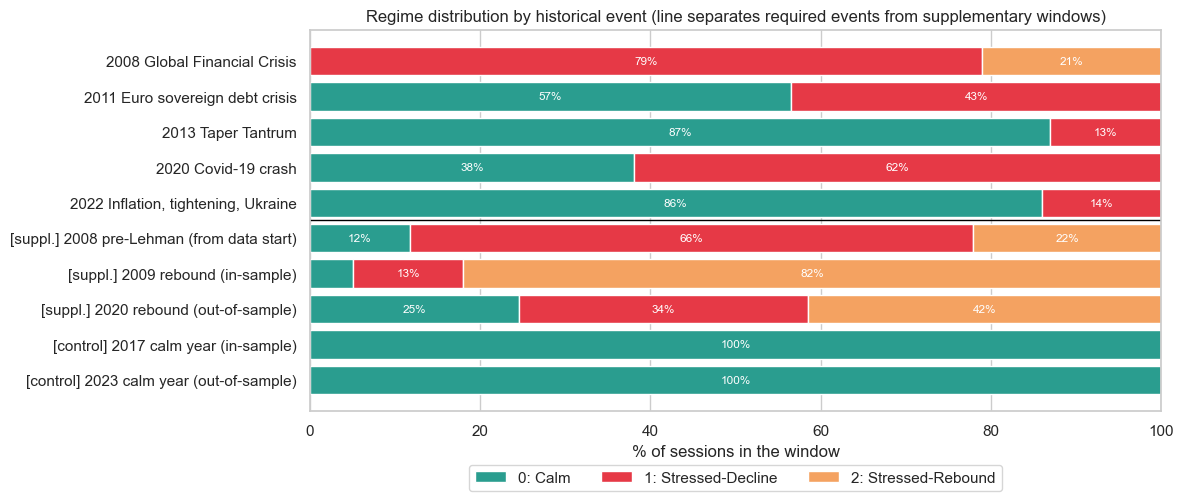

In [8]:
# Figure 2: regime mix inside each event window
plot_ev = ev.set_index("Historical Event")[["share Calm %", "share Decline %", "share Rebound %"]]
fig, ax = plt.subplots(figsize=(12, 5.2))
left = np.zeros(len(plot_ev))
for col, k in zip(plot_ev.columns, REGIME_IDS):
    ax.barh(plot_ev.index, plot_ev[col], left=left, color=COLORS[k], label=LABELS[k], edgecolor="white")
    for i, (v, l) in enumerate(zip(plot_ev[col], left)):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left += plot_ev[col].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of sessions in the window")
ax.axhline(4.5, color="black", lw=1)
ax.set_title("Regime distribution by historical event (line separates required events from supplementary windows)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
save_fig("event_distribution")

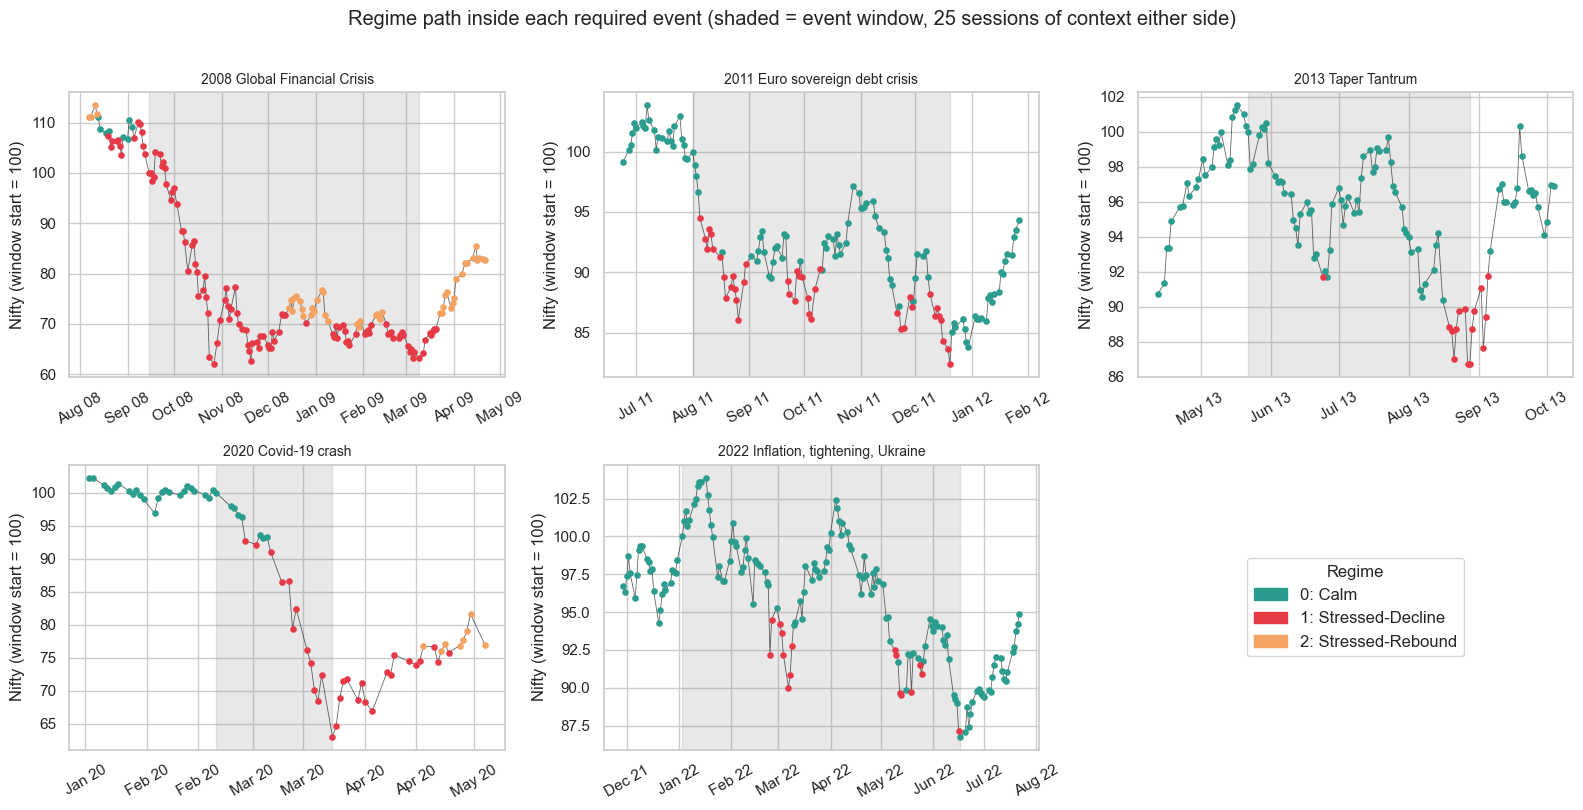

In [10]:
# Figure 3: zoom on each required event (rebased Nifty, coloured by regime, +/- 25 sessions of context)
req = [e for e in EVENTS if e[4] == "required"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax_, (key, label, a, b, role) in zip(axes.ravel(), req):
    i0, i1 = close.index.get_loc(close.loc[a:b].index[0]), close.index.get_loc(close.loc[a:b].index[-1])
    seg = slice(max(i0 - 25, 0), min(i1 + 26, len(close)))
    px = close.iloc[seg]; rg = reg.iloc[seg]
    base = float(close.loc[a:b].iloc[0])
    ax_.plot(px.index, px / base * 100, color="black", lw=.6, alpha=.6)
    for k in REGIME_IDS:
        m = rg == k
        ax_.scatter(px.index[m], (px / base * 100)[m], s=14, color=COLORS[k], zorder=3)
    ax_.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=.18)
    ax_.set_title(label, fontsize=10); ax_.set_ylabel("Nifty (window start = 100)")
    ax_.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax_.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
axes.ravel()[-1].legend(handles=[Patch(color=COLORS[k], label=LABELS[k]) for k in REGIME_IDS], loc="center", fontsize=12, title="Regime")
fig.suptitle("Regime path inside each required event (shaded = event window, 25 sessions of context either side)", y=1.01)
save_fig("event_zoom")


**Interpretation of 7.1**

1. **Two of the five required events are clearly recognised, three are not.** The 2008 crisis (79% Stressed-Decline, 21% Stressed-Rebound, never Calm, India VIX averaging 48) and the 2020 crash (62% Stressed-Decline, and the stressed run from 6 March to the 23 March low covers a 31% fall) fit the Phase 6 profiles. In 2011, 2013 and 2022 the **dominant regime is Calm** (57%, 87% and 86% of sessions), and the stressed labels sit in a few short runs, often in the sharpest weeks (19-28 Aug 2013, 2-9 March 2022, August and December 2011). I did not change anything to make these look better.
2. **Why the weaker events look "mostly Calm" (reasons, not proven here):** the regimes are built mostly from equity volatility, VIX, drawdown and stock correlation (the PC1 loadings in Phase 6). India VIX peaked at only 32 in 2013 and 2022 and 37 in 2011, against 85 in 2008 and 72 in 2020 inside the windows. 2013 was largely a currency and bond-yield shock and 2022 a slow tightening drift, neither of which needs high equity volatility. There is also a scale effect: the stressed regimes are defined relative to a training sample that contains 2008-09, so a VIX of 30 is only borderline. Section 7.4 gives direct evidence for this last point.
3. **The labels lag the market.** In the four events where the first day was not already stressed, the first stressed label came after the Nifty had fallen 5.5% (2011, 4 sessions in), 8.3% (2013, 23 sessions in), 7.3% (2020, 5 sessions in) and 7.8% (2022, 37 sessions in). The inputs are trailing windows (10, 21 and 63 days) and VIX, so the regime reacts after the first leg down. This matters for Phase 9: a regime-based exposure rule cannot avoid the first part of a fall.
4. **Calm is not over-triggered.** The two quiet control years, 2017 (in-sample) and 2023 (out-of-sample), are 100% Calm with zero switches. Combined with point 1, the model has high specificity but modest sensitivity to milder stress.
5. **The rebound regime is only partly validated.** In the 2009 rebound it holds 82% of sessions, but that window is the training data that defined the cluster. In the out-of-sample 2020 rebound it is the most common label at only 42% (34% Stressed-Decline, 25% Calm). Rebound labels also appear inside the 2008 crisis (24 sessions, bear-market rallies), which is consistent with its profile (sharp rises while the market is still deeply below its peak).
6. **Switching inside events:** 8 switches in the 114-session 2008 window, 13 in 2011 and 14 in 2022. As expected, a stress episode is not one block. The 2011 and 2022 windows contain 7 separate stressed runs each, which previews the flicker found in 7.3.

**Limits of this evidence:** the windows were chosen by us with hindsight (a different window for 2022, such as the full calendar year, gives 94% Calm; see the sensitivity table), and the 2008 window is in-sample. This shows the labels are **not obviously wrong and not trigger-happy**, and that they capture severe volatility stress. It does not show that they are objectively correct.


## 4. 7.2 Statistical characteristics of each regime

**What:** for each regime, the mean and volatility of Nifty daily log returns, the mean India VIX, the number of days, and some downside measures (5th percentile, worst day, share of days below -2%, skewness).

**Why these indicators:** regimes in this project are defined as *states of market risk*, so the most direct test is whether risk differs between them. Return volatility is the realised measure of risk, India VIX is the market's own forward-looking estimate of it, and the lower tail of returns is what the later risk overlay (VaR, drawdown) actually cares about. Mean return is included because the exposure rule only makes sense if stressed regimes are *not* compensated enough for their risk. Cluster size alone says nothing about any of this: a cluster can be large and indistinguishable from its neighbour.

**Why descriptive statistics first:** they show the size of the differences. A p-value only says whether a difference is distinguishable from zero, not whether it matters, and with strongly autocorrelated daily data it can be badly misleading (see below).

**Units:** daily figures are the primary numbers. Annualised figures are daily mean x 252 and daily standard deviation x sqrt(252), shown only for comparability with VIX (which is quoted in annualised percent). **Annualised mean returns for the stressed regimes are not meaningful forecasts**: they come from a few hundred days in a few episodes and are shown only so the units match.

### What is internal consistency and what is independent evidence

This is the most important caveat of the section. Phase 5 used Nifty 1-day, 5-day and 21-day returns, three Nifty volatility windows, drawdown and **India VIX as clustering inputs**. So a table of same-day return, volatility and VIX by regime is an **internal consistency check**: the regimes were built to separate exactly these variables, so they should differ. It confirms that the clusters are not degenerate, nothing more.

Evidence that is at least partly independent of the inputs:

| Variable | Why it is (partly) independent |
|---|---|
| **Next-day absolute return** and **forward 21-day realised volatility** (sessions *t+1* to *t+21*) | Not inputs to the label on day *t*. This is the real test: does today's regime tell us something about the risk that follows? |
| **Forward 21-day return** | Same; used to check whether stress is *followed* by lower returns. |
| **Sensex and Nifty IT realised volatility** | Neither is a feature (the outline keeps Sensex as a cross-check only). **Weak independence:** both move closely with the Nifty (Sensex correlation with the Nifty is 0.99), so this mostly confirms the Nifty result. Nifty IT (correlation 0.65) is more independent. |

Two limits remain even for the forward variables: the stressed regimes come from two crisis episodes, and forward windows overlap from one day to the next.

**Hypothesis tests.** Two features of the data make textbook tests unreliable here. Regimes are persistent (7.3), and daily squared returns are strongly autocorrelated (volatility clustering, Phase 3). Consecutive observations are therefore far from independent, the effective sample size is much smaller than the row count, and a Kruskal-Wallis or t-test p-value would be extremely small for almost any split of this data, whether or not the regimes are real. Return distributions are also fat-tailed (Phase 3), which rules out normality-based tests. I therefore **do not report such p-values**. Instead the notebook uses a **circular block bootstrap** (resample 21-session blocks, which keeps short-run dependence and the run structure of the regimes) to get a 95% interval for each regime statistic and for the **difference between regimes**. An interval that excludes zero is evidence of a difference *given the episodes we have*. Its limits: a 21-session block is shorter than the long Calm run (990 sessions) and than the 2008 episode, so the intervals are likely still too narrow, and no bootstrap can create more independent crises than the sample contains.

In [9]:
def stats_block(r, g, vix, ids=REGIME_IDS):
    rows = {}
    for k in ids:
        x = r[g == k]
        rows[k] = {
            "Days": int(len(x)),
            "Mean Return (daily, %)": float(x.mean() * 100),
            "Mean Return (annualised, %)": float(x.mean() * TRADING_DAYS * 100),
            "Volatility (daily, %)": float(x.std() * 100),
            "Volatility (annualised, %)": float(x.std() * np.sqrt(TRADING_DAYS) * 100),
            "Mean India VIX": float(vix[g == k].mean()),
            "5th pct daily return (%)": float(x.quantile(.05) * 100),
            "Worst day (%)": float(x.min() * 100),
            "Days below -2% (%)": float((x < -0.02).mean() * 100),
            "Skewness": float(x.skew()),
        }
    out = pd.DataFrame.from_dict(rows, orient="index")
    out.index = [LABELS[i] for i in out.index]
    out.index.name = "Regime"
    return out

vix = regimes["vix_level"]
stats_all = stats_block(ret, reg, vix)
print("ALL SESSIONS (internal consistency: these variables were clustering inputs)")
display(stats_all.round(2))

for name, m in [("TRAIN 2008-2017", split == "train"), ("TEST 2018-Oct 2026 (labels assigned with predict)", split == "test")]:
    print(name)
    display(stats_block(ret[m], reg[m], vix[m])[["Days", "Mean Return (daily, %)", "Volatility (annualised, %)", "Mean India VIX", "5th pct daily return (%)", "Worst day (%)", "Days below -2% (%)"]].round(2))

ALL SESSIONS (internal consistency: these variables were clustering inputs)


,Days,"Mean Return (daily, %)","Mean Return (annualised, %)","Volatility (daily, %)","Volatility (annualised, %)",Mean India VIX,5th pct daily return (%),Worst day (%),Days below -2% (%),Skewness
Regime,,,,,,,,,,
0: Calm,4040,0.06,15.64,0.90,14.34,17.19,-1.44,-4.17,1.66,0.08
1: Stressed-Decline,307,-0.65,-163.06,2.86,45.43,38.32,-4.87,-13.90,30.62,-0.32
2: Stressed-Rebound,162,0.66,166.59,2.37,37.64,41.85,-2.89,-6.38,9.88,1.45


TRAIN 2008-2017


,Days,"Mean Return (daily, %)","Volatility (annualised, %)",Mean India VIX,5th pct daily return (%),Worst day (%),Days below -2% (%)
Regime,,,,,,,
0: Calm,1957,0.07,15.17,18.52,-1.50,-4.17,1.99
1: Stressed-Decline,244,-0.55,41.98,37.87,-4.25,-13.01,27.87
2: Stressed-Rebound,135,0.62,39.21,43.32,-2.90,-6.38,11.11


TEST 2018-Oct 2026 (labels assigned with predict)


,Days,"Mean Return (daily, %)","Volatility (annualised, %)",Mean India VIX,5th pct daily return (%),Worst day (%),Days below -2% (%)
Regime,,,,,,,
0: Calm,2083,0.06,13.52,15.93,-1.34,-3.84,1.34
1: Stressed-Decline,63,-1.01,56.88,40.04,-6.07,-13.90,41.27
2: Stressed-Rebound,27,0.88,28.88,34.52,-1.40,-5.92,3.70


Overall Spearman correlation of trailing 21d volatility and India VIX: 0.814


,"corr(21d vol, VIX), Spearman",days
0: Calm,0.75,4040
1: Stressed-Decline,0.86,307
2: Stressed-Rebound,0.19,162


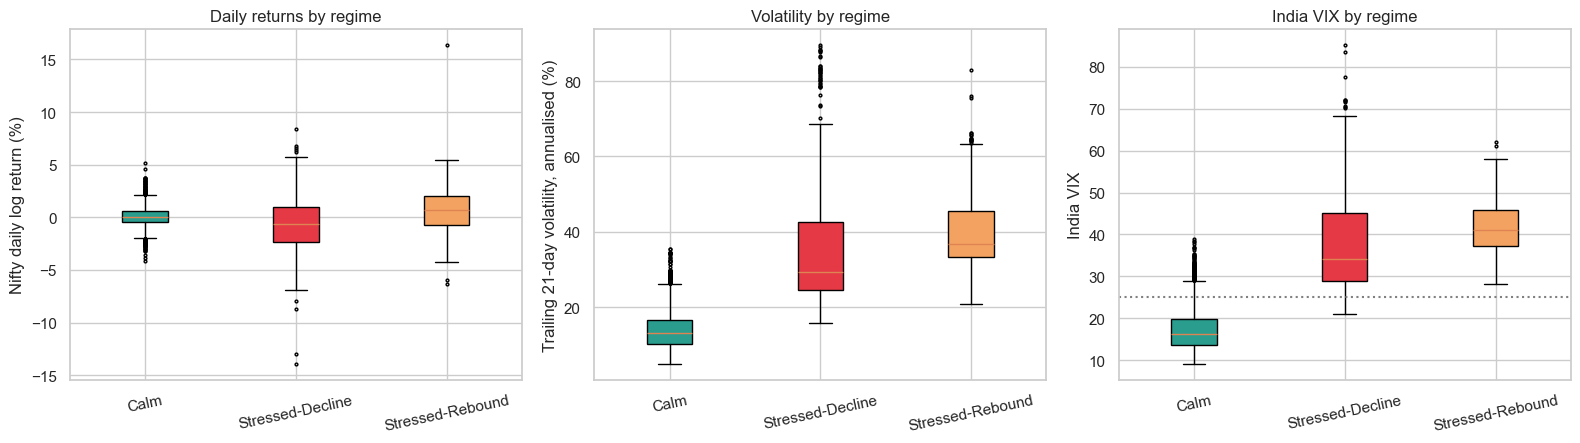

In [10]:
# Does higher return volatility go with higher VIX *within* a regime, or only between regimes?
tv = features["nifty_vol_21d"]
within = {}
for k in REGIME_IDS:
    m = reg == k
    within[LABELS[k]] = {"corr(21d vol, VIX), Spearman": float(tv[m].corr(vix[m], method="spearman")), "days": int(m.sum())}
print("Overall Spearman correlation of trailing 21d volatility and India VIX:", round(float(tv.corr(vix, method="spearman")), 3))
display(pd.DataFrame.from_dict(within, orient="index").round(2))

def colored_box(ax_, series_by_regime, ylabel, title):
    # no 'labels'/'tick_labels' keyword: its name differs between matplotlib versions
    bp = ax_.boxplot(series_by_regime, patch_artist=True, flierprops={"markersize": 2})
    for patch, k in zip(bp["boxes"], REGIME_IDS):
        patch.set_facecolor(COLORS[k])
    ax_.set_xticks(range(1, len(REGIME_IDS) + 1)); ax_.set_xticklabels([REGIME_NAMES[k] for k in REGIME_IDS], rotation=12)
    ax_.set_ylabel(ylabel); ax_.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
colored_box(ax[0], [ret[reg == k] * 100 for k in REGIME_IDS], "Nifty daily log return (%)", "Daily returns by regime")
colored_box(ax[1], [tv[reg == k] * 100 for k in REGIME_IDS], "Trailing 21-day volatility, annualised (%)", "Volatility by regime")
colored_box(ax[2], [vix[reg == k] for k in REGIME_IDS], "India VIX", "India VIX by regime")
ax[2].axhline(25, ls=":", color="grey")
save_fig("boxplots")

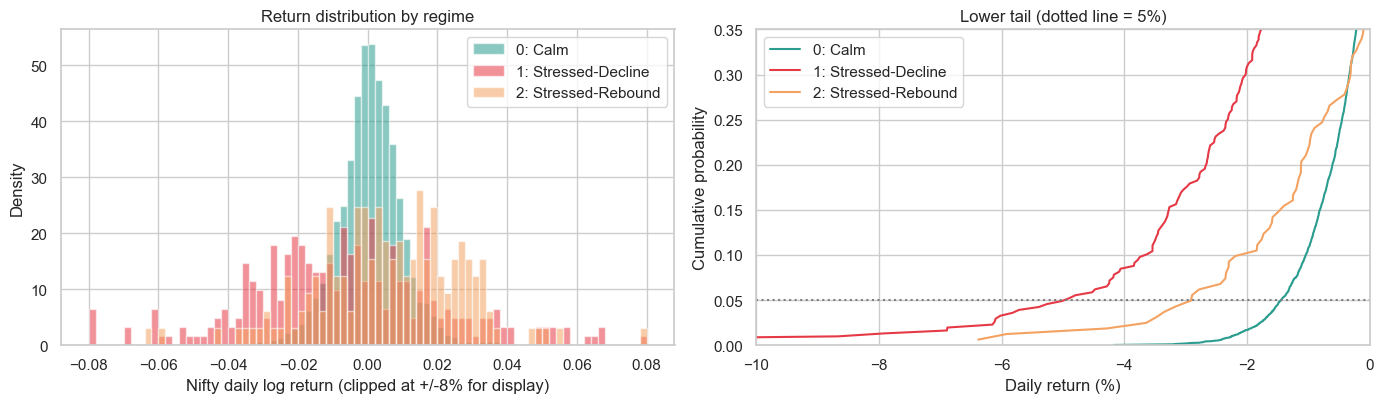

In [13]:
# Return distributions: overlaid histograms + empirical lower tail
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
bins = np.linspace(-0.08, 0.08, 81)
for k in REGIME_IDS:
    ax[0].hist(np.clip(ret[reg == k], -0.08, 0.08), bins=bins, density=True, alpha=.55, color=COLORS[k], label=LABELS[k])
ax[0].set_xlabel("Nifty daily log return (clipped at +/-8% for display)"); ax[0].set_ylabel("Density"); ax[0].legend(); ax[0].set_title("Return distribution by regime")
for k in REGIME_IDS:
    x = np.sort(ret[reg == k].to_numpy()); p = np.arange(1, len(x) + 1) / len(x)
    ax[1].plot(x * 100, p, color=COLORS[k], label=LABELS[k])
ax[1].set_xlim(-10, 0); ax[1].set_ylim(0, .35); ax[1].axhline(.05, ls=":", color="grey")
ax[1].set_xlabel("Daily return (%)"); ax[1].set_ylabel("Cumulative probability"); ax[1].set_title("Lower tail (dotted line = 5%)"); ax[1].legend()
save_fig("return_distributions")


**Interpretation (same-day statistics, an internal consistency check)**

| | Calm | Stressed-Decline | Stressed-Rebound |
|---|---|---|---|
| Days | 4,040 | 307 | 162 |
| Mean daily return | +0.06% | -0.65% | +0.66% |
| Volatility (annualised) | 14.3% | 45.4% | 37.6% |
| Mean India VIX | 17.2 | 38.3 | 41.9 |
| 5th percentile of daily return | -1.44% | -4.87% | -2.89% |
| Worst day | -4.2% | -13.9% | -6.4% |
| Days below -2% | 1.7% | 30.6% | 9.9% |
| Skewness | +0.08 | -0.32 | +1.45 |

- **The regimes differ sharply, but this is expected.** Returns, three volatility windows, drawdown and VIX were inputs to the clustering, so this table shows only that the clusters are not degenerate. It is not independent evidence (see the next sub-section for that).
- **Calm vs stressed is a difference in kind.** Volatility is roughly three times higher in the stressed regimes, and the lower tail is much heavier: nearly a third of Stressed-Decline days lose more than 2%, against under 2% in Calm.
- **Higher volatility goes with higher VIX between Calm and the stressed regimes, but the two stressed regimes order differently:** Stressed-Decline has the highest realised volatility (45%), Stressed-Rebound the highest VIX (42). Within regimes, the rank correlation of trailing volatility and VIX is 0.75 in Calm and 0.86 in Stressed-Decline but only **0.19 in Stressed-Rebound**. That fits a post-crash pattern in which VIX stays high while realised volatility has started to fall, although I did not test it further.
- **The names are supported by the numbers.** *Calm*: lowest volatility and VIX, small positive mean, few large losses. *Stressed-Decline*: negative mean, the heaviest downside, negative skew. *Stressed-Rebound*: positive mean and strongly positive skew (+1.45) while volatility and VIX are still high; it is not a calm recovery, which is why the word "Recovery" was not used.
- **Annualised mean returns (-163%, +167%) are not meaningful.** They multiply a daily mean from a few hundred days in one or two episodes by 252, and they are largely circular (the return inputs define the clusters).
- **Train vs test:** the pattern holds out-of-sample, but the test stressed regimes are small (63 and 27 days). Stressed-Decline is more extreme in test (volatility 57%, worst day -13.9% in March 2020), while Stressed-Rebound is milder in test (volatility 29%, VIX 35, 3.7% of days below -2%) than in training (39%, VIX 43, 11.1%).


### Independent evidence: what happens *after* the label

Everything below uses information from sessions **after** day *t* (or series that are not clustering inputs), so it is a genuine out-of-input test of the regime label on day *t*. It is **not** a trading signal: nothing here is tradable until Phases 8 and 9 test it with the one-day lag.

In [11]:
nxt = ret.shift(-1)                                                      # return of session t+1
indep = pd.DataFrame({
    "regime": reg, "split": split,
    "next_abs_ret_pct": nxt.abs() * 100,
    "fwd21_vol_pct": ret.rolling(21).std().shift(-21) * np.sqrt(TRADING_DAYS) * 100,   # realised vol over sessions t+1..t+21
    "fwd21_ret_pct": ret.rolling(21).sum().shift(-21) * 100,                           # log return over sessions t+1..t+21
    "sensex": np.log(clean["sensex"]).diff().reindex(regimes.index),
    "nifty_it": np.log(clean["nifty_it"]).diff().reindex(regimes.index),
})
print("Forward variables are NaN for the last 21 sessions:", int(indep["fwd21_vol_pct"].isna().sum()), "rows")
assert abs(float(indep.loc[indep.index[100], "fwd21_vol_pct"] - ret.iloc[101:122].std() * np.sqrt(TRADING_DAYS) * 100)) < 1e-9   # window really is t+1..t+21

def indep_table(d):
    rows = {}
    for k in REGIME_IDS:
        x = d[d["regime"] == k]
        rows[LABELS[k]] = {
            "Days": int(len(x)),
            "Next-day |return| (%)": float(x["next_abs_ret_pct"].mean()),
            "Forward 21d volatility (ann., %)": float(x["fwd21_vol_pct"].mean()),
            "Forward 21d return (%)": float(x["fwd21_ret_pct"].mean()),
            "Sensex volatility (ann., %)": float(x["sensex"].std() * np.sqrt(TRADING_DAYS) * 100),
            "Nifty IT volatility (ann., %)": float(x["nifty_it"].std() * np.sqrt(TRADING_DAYS) * 100),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

indep_all = indep_table(indep)
print("ALL SESSIONS")
display(indep_all.round(2))
print("TEST PERIOD ONLY (2018 onwards)")
display(indep_table(indep[indep["split"] == "test"]).round(2))

Forward variables are NaN for the last 21 sessions: 21 rows
ALL SESSIONS


,Days,Next-day |return| (%),"Forward 21d volatility (ann., %)",Forward 21d return (%),"Sensex volatility (ann., %)","Nifty IT volatility (ann., %)"
0: Calm,4040,0.69,14.26,0.59,14.25,20.20
1: Stressed-Decline,307,2.05,36.82,1.37,46.58,46.05
2: Stressed-Rebound,162,1.75,35.35,4.31,38.48,39.27


TEST PERIOD ONLY (2018 onwards)


,Days,Next-day |return| (%),"Forward 21d volatility (ann., %)",Forward 21d return (%),"Sensex volatility (ann., %)","Nifty IT volatility (ann., %)"
0: Calm,2083,0.66,13.60,0.57,13.58,20.75
1: Stressed-Decline,63,2.45,37.95,3.73,58.06,54.71
2: Stressed-Rebound,27,1.29,23.66,5.46,29.58,29.03


In [12]:
def block_bootstrap(r, g, fwd_vol, B=2000, block=21, seed=SEED):
    """Circular block bootstrap of (return, regime, forward-vol) triples. Returns per-draw statistics for each regime."""
    rng = np.random.default_rng(seed)
    n = len(r); nb = int(np.ceil(n / block))
    r_, g_, f_ = r.to_numpy(), g.to_numpy(), fwd_vol.to_numpy()
    out = {k: {"ann_vol": np.full(B, np.nan), "mean_ret": np.full(B, np.nan), "fwd_vol": np.full(B, np.nan)} for k in REGIME_IDS}
    for b in range(B):
        starts = rng.integers(0, n, nb)
        idx = ((starts[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]
        gi, ri, fi = g_[idx], r_[idx], f_[idx]
        for k in REGIME_IDS:
            m = gi == k
            if m.sum() >= 5:
                out[k]["ann_vol"][b] = ri[m].std(ddof=1) * np.sqrt(TRADING_DAYS) * 100
                out[k]["mean_ret"][b] = ri[m].mean() * 100
                fm = fi[m]
                out[k]["fwd_vol"][b] = np.nanmean(fm) if np.isfinite(fm).any() else np.nan
    return out

B_DRAWS, BLOCK = 2000, 21
boot = block_bootstrap(ret, reg, indep["fwd21_vol_pct"], B=B_DRAWS, block=BLOCK)
lo_hi = lambda a: (float(np.nanpercentile(a, 2.5)), float(np.nanpercentile(a, 97.5)))

ci_rows = {}
for k in REGIME_IDS:
    ci_rows[LABELS[k]] = {}
    for stat, label in [("ann_vol", "Volatility (ann., %)"), ("mean_ret", "Mean daily return (%)"), ("fwd_vol", "Forward 21d volatility (ann., %)")]:
        lo, hi = lo_hi(boot[k][stat]); ci_rows[LABELS[k]][label] = f"[{lo:.2f}, {hi:.2f}]"
print(f"95% circular block-bootstrap intervals ({B_DRAWS} draws, block = {BLOCK} sessions, seed {SEED})")
display(pd.DataFrame.from_dict(ci_rows, orient="index"))

pairs = [(1, 0, "Stressed-Decline minus Calm"), (2, 0, "Stressed-Rebound minus Calm"), (2, 1, "Stressed-Rebound minus Stressed-Decline")]
diff_rows = {}
for a, b, label in pairs:
    diff_rows[label] = {}
    for stat, sl in [("ann_vol", "Volatility (ann., pp)"), ("mean_ret", "Mean daily return (pp)"), ("fwd_vol", "Forward 21d vol (pp)")]:
        d = boot[a][stat] - boot[b][stat]; lo, hi = lo_hi(d)
        point = {"ann_vol": float(ret[reg == a].std() - ret[reg == b].std()) * np.sqrt(TRADING_DAYS) * 100,
                 "mean_ret": float(ret[reg == a].mean() - ret[reg == b].mean()) * 100,
                 "fwd_vol": float(indep.loc[reg == a, "fwd21_vol_pct"].mean() - indep.loc[reg == b, "fwd21_vol_pct"].mean())}[stat]
        diff_rows[label][sl] = f"{point:+.2f}  [{lo:+.2f}, {hi:+.2f}]" + ("  *" if (lo > 0 or hi < 0) else "")
print("Differences between regimes: point estimate [95% interval]; * = interval excludes zero")
display(pd.DataFrame.from_dict(diff_rows, orient="index"))

# how sensitive are the intervals to the block length?
sens = []
for blk in (10, 21, 42, 63):
    bb = block_bootstrap(ret, reg, indep["fwd21_vol_pct"], B=500, block=blk)
    for a, b, label in pairs[:1] + pairs[2:]:
        lo, hi = lo_hi(bb[a]["ann_vol"] - bb[b]["ann_vol"])
        sens.append({"block length": blk, "difference": label, "95% interval, volatility (pp)": f"[{lo:+.1f}, {hi:+.1f}]"})
print("Sensitivity of the volatility-difference intervals to the block length (500 draws each)")
display(pd.DataFrame(sens).pivot(index="block length", columns="difference", values="95% interval, volatility (pp)"))

95% circular block-bootstrap intervals (2000 draws, block = 21 sessions, seed 42)


,"Volatility (ann., %)",Mean daily return (%),"Forward 21d volatility (ann., %)"
0: Calm,"[13.76, 14.98]","[0.03, 0.09]","[13.57, 15.03]"
1: Stressed-Decline,"[34.32, 54.74]","[-0.93, -0.39]","[28.84, 44.26]"
2: Stressed-Rebound,"[28.57, 46.83]","[0.35, 0.97]","[28.01, 42.58]"


Differences between regimes: point estimate [95% interval]; * = interval excludes zero


,"Volatility (ann., pp)",Mean daily return (pp),Forward 21d vol (pp)
Stressed-Decline minus Calm,"+31.09 [+20.19, +40.59] *","-0.71 [-0.99, -0.45] *","+22.56 [+14.62, +30.10] *"
Stressed-Rebound minus Calm,"+23.30 [+14.27, +32.49] *","+0.60 [+0.28, +0.90] *","+21.09 [+13.61, +28.27] *"
Stressed-Rebound minus Stressed-Decline,"-7.79 [-21.39, +5.32]","+1.31 [+0.94, +1.70] *","-1.47 [-11.84, +8.90]"


Sensitivity of the volatility-difference intervals to the block length (500 draws each)


difference,Stressed-Decline minus Calm,Stressed-Rebound minus Stressed-Decline
block length,,
10,"[+23.2, +39.4]","[-20.8, +5.4]"
21,"[+20.5, +39.8]","[-21.7, +5.6]"
42,"[+18.8, +40.4]","[-21.5, +7.4]"
63,"[+18.1, +40.7]","[-21.1, +7.9]"


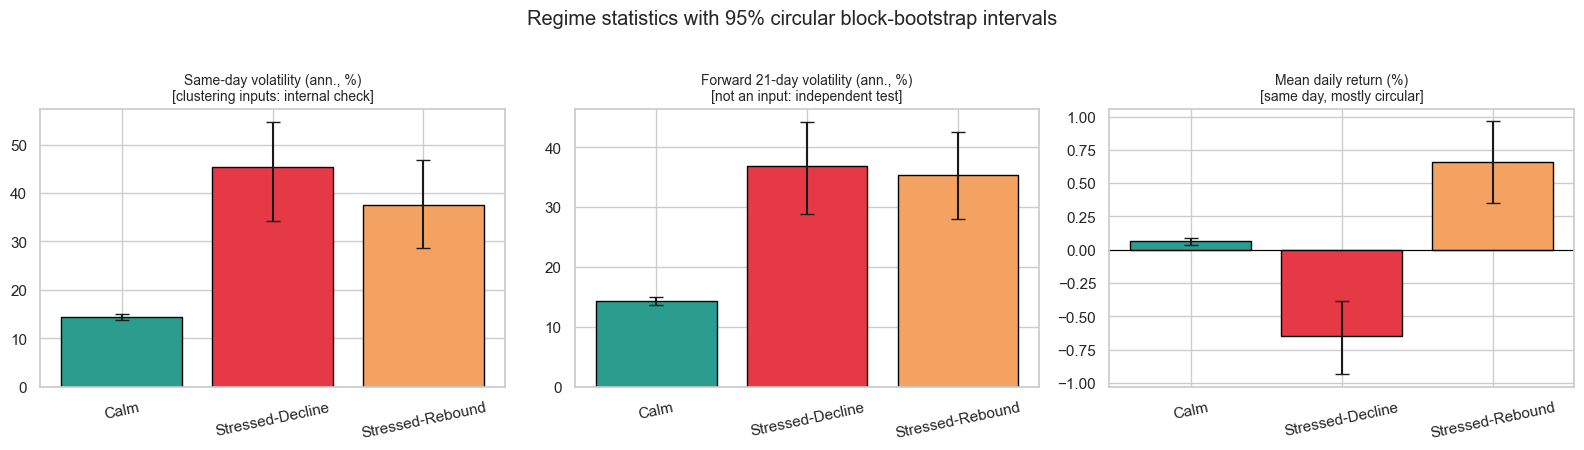

In [14]:
# Figure: same-day vs forward evidence, with bootstrap intervals
panels = [("ann_vol", "Same-day volatility (ann., %)\n[clustering inputs: internal check]", lambda k: float(ret[reg == k].std() * np.sqrt(TRADING_DAYS) * 100)),
          ("fwd_vol", "Forward 21-day volatility (ann., %)\n[not an input: independent test]", lambda k: float(indep.loc[reg == k, "fwd21_vol_pct"].mean())),
          ("mean_ret", "Mean daily return (%)\n[same day, mostly circular]", lambda k: float(ret[reg == k].mean() * 100))]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a_, (stat, title, fn) in zip(ax, panels):
    pts = [fn(k) for k in REGIME_IDS]
    ci = [lo_hi(boot[k][stat]) for k in REGIME_IDS]
    err = np.array([[p - c[0] for p, c in zip(pts, ci)], [c[1] - p for p, c in zip(pts, ci)]])
    a_.bar([REGIME_NAMES[k] for k in REGIME_IDS], pts, color=[COLORS[k] for k in REGIME_IDS], yerr=err, capsize=5, edgecolor="black")
    a_.set_title(title, fontsize=10); a_.axhline(0, color="black", lw=.8); a_.tick_params(axis="x", rotation=12)
fig.suptitle("Regime statistics with 95% circular block-bootstrap intervals", y=1.02)
save_fig("regime_stats_bootstrap")

### Do the three regimes add anything beyond a simple VIX rule?

This is the sharpest version of the "arbitrary clusters" question. Forward volatility is highly predictable from the *current level of volatility*, so a regime label could look good simply because it is a discretised VIX. The fair comparison is a trivial rule with the **same group sizes** as the regimes (top 3.6% of days by VIX, next 6.8%, the rest), and the usual single threshold (VIX above 25). We measure R-squared: the share of the variance of the forward variable explained by group membership. A continuous VIX fit (squared correlation) is shown as a ceiling for what VIX alone can do.

In [15]:
def r2_groups(y, g):
    d = pd.DataFrame({"y": y, "g": g}).dropna()
    gm = d.groupby("g")["y"].transform("mean")
    return float(1 - ((d["y"] - gm) ** 2).sum() / ((d["y"] - d["y"].mean()) ** 2).sum())

share = reg.value_counts(normalize=True).sort_index()
q1, q2 = vix.quantile(1 - share[1] - share[2]), vix.quantile(1 - share[2])
vix_buckets = pd.cut(vix, [-np.inf, q1, q2, np.inf], labels=[0, 1, 2])          # same sizes as the three regimes
tv_q1, tv_q2 = tv.quantile(1 - share[1] - share[2]), tv.quantile(1 - share[2])
tv_buckets = pd.cut(tv, [-np.inf, tv_q1, tv_q2, np.inf], labels=[0, 1, 2])
vix_gt25 = (vix > 25).astype(int)
targets = {"Forward 21d volatility": indep["fwd21_vol_pct"], "Next-day |return|": indep["next_abs_ret_pct"]}
rows = {}
for period, m in [("all sessions", np.ones(len(reg), bool)), ("test period", (split == "test").to_numpy())]:
    for tname, y in targets.items():
        yy = y[m]
        rows[(period, tname)] = {
            "3 regimes (Phase 6)": r2_groups(yy, reg[m]),
            "VIX, 3 size-matched buckets": r2_groups(yy, vix_buckets[m]),
            "Trailing 21d vol, 3 size-matched buckets": r2_groups(yy, tv_buckets[m]),
            "VIX > 25 (2 groups)": r2_groups(yy, vix_gt25[m]),
            "Continuous VIX (corr squared)": float(pd.concat([yy, vix[m]], axis=1).dropna().corr().iloc[0, 1] ** 2),
        }
bench = pd.DataFrame.from_dict(rows, orient="index"); bench.index.names = ["period", "target"]
print(f"VIX cut points for the size-matched buckets: {q1:.1f} and {q2:.1f}")
display(bench.round(3))

VIX cut points for the size-matched buckets: 29.0 and 42.3


3 regimes (Phase 6)  VIX, 3 size-matched buckets  Trailing 21d vol, 3 size-matched buckets  VIX > 25 (2 groups)  Continuous VIX (corr squared)
period       target                                                                                                                                                                
all sessions Forward 21d volatility                0.417                        0.426                                     0.360                0.327                          0.534
             Next-day |return|                     0.174                        0.183                                     0.168                0.146                          0.245
test period  Forward 21d volatility                0.225                        0.224                                     0.190                0.150                          0.368
             Next-day |return|                     0.151                        0.176                                     0.151                0.124                          0.242


**Interpretation (independent evidence, bootstrap intervals and the VIX benchmark)**

1. **Today's regime says a lot about the risk that follows.** Over all sessions, the next-day absolute return is 0.69% after a Calm day against 2.05% (Stressed-Decline) and 1.75% (Stressed-Rebound). Realised volatility over the next 21 sessions is 14.3% after Calm days against 36.8% and 35.4%. In the test period alone the ordering holds: 13.6% after Calm against 38.0% (Stressed-Decline) and 23.7% (Stressed-Rebound), and next-day absolute return 0.66% against 2.45% and 1.29%. Nifty IT (not a feature, correlation with the Nifty 0.65) shows the same ordering (volatility 20% / 46% / 39%); Sensex is nearly the Nifty (correlation 0.99), so its numbers (14% / 47% / 38%) add little. **This is the strongest piece of evidence in Phase 7**, because the forward variables are not clustering inputs.
2. **The calm-versus-stressed difference is not a sampling accident.** The 95% block-bootstrap intervals for the volatility difference are +20.2 to +40.6 points (Stressed-Decline minus Calm) and +14.3 to +32.5 (Stressed-Rebound minus Calm); for forward 21-day volatility, +14.6 to +30.1 and +13.6 to +28.3. None include zero, and the conclusion is unchanged for block lengths from 10 to 63 sessions. This is evidence given the episodes we have, and the intervals are probably still too narrow because only two big crises drive them.
3. **The two stressed regimes cannot be separated on volatility.** Stressed-Rebound minus Stressed-Decline is -7.8 points [-21.4, +5.3] for same-day volatility and -1.5 [-11.8, +8.9] for forward volatility: both intervals contain zero. They differ in the sign of the mean return (+1.31 points per day [+0.94, +1.70]), but returns are clustering inputs, so that difference is partly built in. What truly distinguishes them is direction, skewness and tail shape, not how risky they are. This confirms the weakness flagged in Phase 6 (the stressed regimes overlap).
4. **The regimes do not beat a simple VIX rule.** Using group membership to explain forward 21-day volatility, the three regimes score R-squared 0.417, against 0.426 for three VIX buckets of the same sizes and 0.327 for a single "VIX above 25" rule; a continuous VIX does better (0.534). In the test period the regimes score 0.225 against 0.224 for the size-matched VIX buckets. For next-day absolute return the regimes (0.174) are again no better than the VIX buckets (0.183). **So the information the regimes carry about future volatility is essentially the information in the VIX level.** The regimes are not worse, so they do track a real risk quantity, but I cannot claim that clustering 21 features adds forecasting power for volatility beyond VIX. Their added value is descriptive (a multi-feature summary and the direction split), not predictive. Phase 8 and 9 should therefore include a plain VIX-threshold rule as a competing baseline.
5. **Stress is followed by higher average returns, not lower** (descriptive only, overlapping 21-day windows, no test attempted): the average next-21-session return is +0.6% after Calm days, +1.4% after Stressed-Decline and +4.3% after Stressed-Rebound (test period: +0.6%, +3.7%, +5.5%). Stress here has been followed by rebounds. An exposure rule that cuts risk in stressed regimes lowers volatility but gives up this average rebound, so Phase 9 must test the Sharpe ratio after costs and must not assume the overlay helps.


## 5. 7.3 Regime transition matrix

**What:** from each pair of consecutive trading sessions (*t*, *t+1*) count how often the regime moves from *i* to *j*, then divide each row by its total:

P(i to j) = (number of sessions where regime *t* = i and regime *t+1* = j) / (number of sessions where regime *t* = i).

**Why row-wise normalisation:** each row is then a probability distribution for "tomorrow's regime given today's regime" and sums to 1. Normalising by the whole table, or by columns, would answer different questions (how common the pair is overall, or where a regime came from).

**What the entries mean:**
- **Diagonal (P(i to i))** is the probability of staying put. It sets the expected duration: if the chance of staying is p, the expected run length is 1 / (1 - p) sessions.
- **Off-diagonal entries** show *how* the market leaves a regime, for example whether stress usually builds through Stressed-Decline first, or whether Calm can jump directly to Stressed-Rebound.

**Use in later phases:** the diagonal is exactly the "tomorrow = today" persistence baseline that Phase 8's classifier has to beat, and the off-diagonal entries (especially Calm to stressed) show how little warning a one-step forecast has. For Phase 9, the exit probabilities from the stressed regimes determine how often an exposure rule would flip back and forth.

**Gaps and boundaries:** a pair is counted only if the two rows are consecutive sessions (calendar gap of at most 7 days, none are excluded here per Section 2). The first row has no predecessor and the last no successor, so *N* sessions give *N - 1* pairs. The train/test boundary is an ordinary pair and is counted in the pooled matrix; the split-specific matrices below count only pairs inside each period, so they omit that one pair.

**Alternatives:** a Markov-chain model with a stationary distribution and multi-step probabilities could be built from this matrix, but it adds nothing to the question "are these regimes persistent and how do they switch?" and assumes the one-step probabilities are constant over time, which the train/test comparison below tests directly.

In [16]:
def transition_counts(g, max_gap=MAX_GAP_DAYS):
    gaps = g.index.to_series().diff().dt.days.to_numpy()[1:]
    ok = gaps <= max_gap                                           # only genuine consecutive-session pairs
    frm, to = g.to_numpy()[:-1][ok], g.to_numpy()[1:][ok]
    M = pd.DataFrame(0, index=REGIME_IDS, columns=REGIME_IDS)
    for a, b in zip(frm, to):
        M.loc[a, b] += 1
    return M, int((~ok).sum())

def row_normalise(M):
    return M.div(M.sum(axis=1), axis=0)

M_all, skipped = transition_counts(reg)
P_all = row_normalise(M_all)
print("Pairs counted:", int(M_all.values.sum()), "= N - 1 =", len(reg) - 1, "| pairs skipped for a calendar gap:", skipped)

named = lambda df: df.rename(index=lambda i: f"From {LABELS[i]}", columns=lambda j: f"To {REGIME_NAMES[j]}")
print("TRANSITION COUNTS (all sessions)"); display(named(M_all))
print("TRANSITION PROBABILITIES (row-normalised)"); display(named(P_all).round(3))
assert np.allclose(P_all.sum(axis=1), 1)

M_tr, _ = transition_counts(reg[split == "train"]); M_te, _ = transition_counts(reg[split == "test"])
P_tr, P_te = row_normalise(M_tr), row_normalise(M_te)
print("TRAINING-PERIOD PROBABILITIES"); display(named(P_tr).round(3))
print("TEST-PERIOD PROBABILITIES"); display(named(P_te).round(3)); print("test-period counts:"); display(named(M_te))
print("Pairs: train", int(M_tr.values.sum()), "+ test", int(M_te.values.sum()), "+ boundary 1 =", int(M_tr.values.sum() + M_te.values.sum() + 1))

implied = {LABELS[k]: 1 / (1 - P_all.loc[k, k]) for k in REGIME_IDS}
persist_acc = float(np.trace(M_all.to_numpy()) / M_all.values.sum())
persist_acc_te = float(np.trace(M_te.to_numpy()) / M_te.values.sum())
print("Expected run length implied by the diagonal, 1/(1-p):", {k: round(float(v), 1) for k, v in implied.items()})
print(f"'Tomorrow = today' accuracy: {persist_acc:.4f} on all pairs | {persist_acc_te:.4f} inside the test period")

Pairs counted: 4508 = N - 1 = 4508 | pairs skipped for a calendar gap: 0
TRANSITION COUNTS (all sessions)


,To Calm,To Stressed-Decline,To Stressed-Rebound
From 0: Calm,3997,39,3
From 1: Stressed-Decline,38,257,12
From 2: Stressed-Rebound,5,10,147


TRANSITION PROBABILITIES (row-normalised)


,To Calm,To Stressed-Decline,To Stressed-Rebound
From 0: Calm,0.990,0.010,0.001
From 1: Stressed-Decline,0.124,0.837,0.039
From 2: Stressed-Rebound,0.031,0.062,0.907


TRAINING-PERIOD PROBABILITIES


,To Calm,To Stressed-Decline,To Stressed-Rebound
From 0: Calm,0.987,0.012,0.001
From 1: Stressed-Decline,0.098,0.865,0.037
From 2: Stressed-Rebound,0.015,0.059,0.926


TEST-PERIOD PROBABILITIES


,To Calm,To Stressed-Decline,To Stressed-Rebound
From 0: Calm,0.992,0.007,0.001
From 1: Stressed-Decline,0.222,0.730,0.048
From 2: Stressed-Rebound,0.111,0.074,0.815


test-period counts:


,To Calm,To Stressed-Decline,To Stressed-Rebound
From 0: Calm,2065,15,2
From 1: Stressed-Decline,14,46,3
From 2: Stressed-Rebound,3,2,22


Pairs: train 2335 + test 2172 + boundary 1 = 4508
Expected run length implied by the diagonal, 1/(1-p): {'0: Calm': 96.2, '1: Stressed-Decline': 6.1, '2: Stressed-Rebound': 10.8}
'Tomorrow = today' accuracy: 0.9763 on all pairs | 0.9820 inside the test period


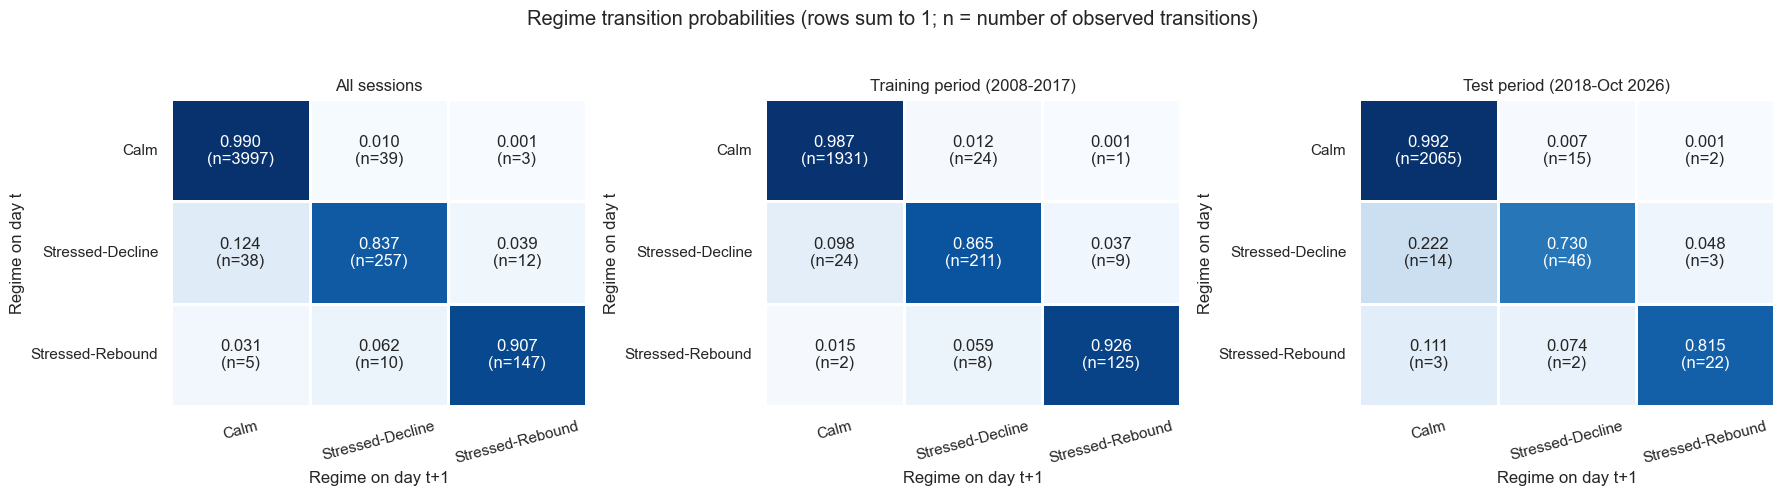

In [17]:
def annotated_heatmap(ax, P, M, title):
    labels = np.array([[f"{P.loc[i, j]:.3f}\n(n={int(M.loc[i, j])})" for j in REGIME_IDS] for i in REGIME_IDS])
    sns.heatmap(P, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, linewidths=1, linecolor="white")
    ax.set_xticklabels([REGIME_NAMES[j] for j in REGIME_IDS], rotation=15); ax.set_yticklabels([REGIME_NAMES[i] for i in REGIME_IDS], rotation=0)
    ax.set_xlabel("Regime on day t+1"); ax.set_ylabel("Regime on day t"); ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
annotated_heatmap(ax[0], P_all, M_all, "All sessions")
annotated_heatmap(ax[1], P_tr, M_tr, "Training period (2008-2017)")
annotated_heatmap(ax[2], P_te, M_te, "Test period (2018-Oct 2026)")
fig.suptitle("Regime transition probabilities (rows sum to 1; n = number of observed transitions)", y=1.03)
save_fig("transition_heatmaps")


**Interpretation of the transition matrix**

| From \ To (next session) | Calm | Stressed-Decline | Stressed-Rebound |
|---|---|---|---|
| **Calm** | 0.990 | 0.010 | 0.001 |
| **Stressed-Decline** | 0.124 | 0.837 | 0.039 |
| **Stressed-Rebound** | 0.031 | 0.062 | 0.907 |

- **All three regimes are sticky at the daily horizon.** Calm stays Calm 99.0% of the time (expected run of 96 sessions); Stressed-Rebound 90.7% (about 11 sessions); Stressed-Decline 83.7% (about 6 sessions).
- **Stress arrives through Stressed-Decline.** Calm moves to Stressed-Decline 39 times but to Stressed-Rebound only 3 times, and Stressed-Rebound is entered from Stressed-Decline 12 times. The typical path is Calm, then Stressed-Decline, then possibly Stressed-Rebound, which fits a crash followed by a rebound.
- **Rebounds are fragile.** From Stressed-Rebound the market went back to Stressed-Decline 10 times and to Calm 5 times (6.2% against 3.1% per session). These are small counts, but a rebound is more often followed by renewed stress than by a clean return to Calm.
- **The stressed regimes are less persistent in the test period.** Staying probabilities, training against test: Stressed-Decline 0.865 against 0.730, Stressed-Rebound 0.926 against 0.815, Calm 0.987 against 0.992. The test estimates rest on only 63 and 27 stressed days (46 and 22 stay-transitions), and 2020 was a brief V-shaped episode against the long 2008-09 crisis, so this is weak evidence, but it means constant transition probabilities are not a safe assumption.
- **For Phase 8:** the persistence baseline ("tomorrow = today") is correct **97.6%** of the time (98.2% inside the test period). That number is dominated by Calm (90% of all sessions, 96% of test sessions), so accuracy is almost useless for judging a classifier here. Phase 8 should be compared on the stressed classes (per-class recall and macro-F1), where this baseline's per-class hit rates are the diagonal entries above.
- **For Phase 9:** the exit probability from Stressed-Decline to Calm is 12.4% per session (22% in the test period). A rule that follows the current regime would therefore reverse its exposure often, which means turnover and transaction costs.


## 6. 7.3 Average regime duration

**What:** an *episode* is a maximal run of consecutive sessions with the same regime label. For each regime: the number of episodes and the mean, median, minimum and maximum run length, plus the share of very short episodes.

**Why consecutive trading sessions:** the model sees one observation per session, and the exposure rule in Phase 9 acts once per session. Calendar days would count weekends and holidays, which carry no information and make a Friday-to-Monday run look longer than a Monday-to-Tuesday one.

**Why the mean alone misleads:** run lengths are extremely skewed. A few very long episodes (a Calm run of years) pull the mean far above what a typical episode looks like. The **median** shows the typical episode, the **maximum** and the **share of days sitting in long episodes** show how concentrated the regime is, and the share of **1 to 2 session episodes** shows how much of the regime is noise-like flicker.

**Partial episodes:** the first episode (starting at the first available date) and the last (running to the last date) are cut off by the data window, so their true length is unknown. They are **flagged and reported both ways** (including them, and excluding them). They are counted in the main table because dropping the last Calm episode would drop 139 recent sessions of the current regime, but the sensitivity table shows what changes.

**The train/test boundary:** it is **not** treated as a break. The labels come from one continuous series of sessions (Section 2), so an episode that crosses 2018-01-01 is one episode. The code flags episodes that span it.

**What persistence does and does not show:** the features are built from 10, 21 and 63-day rolling windows, so they change slowly by construction. Some of the persistence seen here is therefore **mechanical smoothing**, not evidence that the market itself switches state slowly. That caveat applies to every persistence number in this notebook.

In [18]:
def build_episodes(g):
    lab = g.to_numpy()
    run_id = np.r_[0, np.cumsum(lab[1:] != lab[:-1])]
    ep = (pd.DataFrame({"run": run_id, "regime": lab, "date": g.index})
            .groupby("run").agg(regime=("regime", "first"), start=("date", "first"), end=("date", "last"), sessions=("date", "size"))
            .reset_index(drop=True))
    ep["left_censored"] = False; ep.loc[0, "left_censored"] = True                      # starts at the first available date
    ep["right_censored"] = False; ep.loc[len(ep) - 1, "right_censored"] = True           # runs to the last available date
    ep["spans_train_test_boundary"] = (ep["start"] <= pd.Timestamp(meta["train_end"])) & (ep["end"] > pd.Timestamp(meta["train_end"]))
    return ep

episodes = build_episodes(reg)
assert int(episodes["sessions"].sum()) == len(reg)                                      # every session belongs to exactly one episode
assert (episodes["regime"].to_numpy()[1:] != episodes["regime"].to_numpy()[:-1]).all()  # neighbouring episodes always differ

def duration_table(ep):
    rows = {}
    for k in REGIME_IDS:
        e = ep[ep["regime"] == k]["sessions"]
        total = e.sum()
        rows[LABELS[k]] = {
            "Episodes": int(len(e)), "Mean (sessions)": float(e.mean()), "Median": float(e.median()), "Min": int(e.min()), "Max": int(e.max()),
            "90th percentile": float(e.quantile(.9)),
            "Episodes <= 2 sessions (%)": float((e <= 2).mean() * 100),
            "Regime days in episodes >= 10 sessions (%)": float(e[e >= 10].sum() / total * 100),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

print("Partial (boundary) episodes:")
display(episodes[episodes["left_censored"] | episodes["right_censored"] | episodes["spans_train_test_boundary"]].assign(regime=lambda d: d["regime"].map(REGIME_NAMES)))
print("DURATION STATISTICS, all episodes (partial ones included)")
display(duration_table(episodes).round(1))
print("SENSITIVITY: partial first/last episodes excluded")
display(duration_table(episodes[~(episodes["left_censored"] | episodes["right_censored"])]).round(1))
print("Expected run length from the transition diagonal, 1/(1-p):", {k: round(float(v), 1) for k, v in implied.items()})

Partial (boundary) episodes:


,regime,start,end,sessions,left_censored,right_censored,spans_train_test_boundary
0,Stressed-Decline,2008-06-09,2008-07-21,31,True,False,False
68,Calm,2016-02-15,2020-02-27,990,False,False,True
107,Calm,2026-04-07,2026-10-27,139,False,True,False


DURATION STATISTICS, all episodes (partial ones included)


,Episodes,Mean (sessions),Median,Min,Max,90th percentile,Episodes <= 2 sessions (%),Regime days in episodes >= 10 sessions (%)
0: Calm,43,94.0,6.0,1,990,340.0,34.9,98.5
1: Stressed-Decline,50,6.1,2.0,1,64,14.1,56.0,59.3
2: Stressed-Rebound,15,10.8,5.0,1,69,18.4,26.7,69.8


SENSITIVITY: partial first/last episodes excluded


,Episodes,Mean (sessions),Median,Min,Max,90th percentile,Episodes <= 2 sessions (%),Regime days in episodes >= 10 sessions (%)
0: Calm,42,92.9,6.0,1,990,353.5,35.7,98.4
1: Stressed-Decline,49,5.6,2.0,1,64,11.6,57.1,54.7
2: Stressed-Rebound,15,10.8,5.0,1,69,18.4,26.7,69.8


Expected run length from the transition diagonal, 1/(1-p): {'0: Calm': 96.2, '1: Stressed-Decline': 6.1, '2: Stressed-Rebound': 10.8}


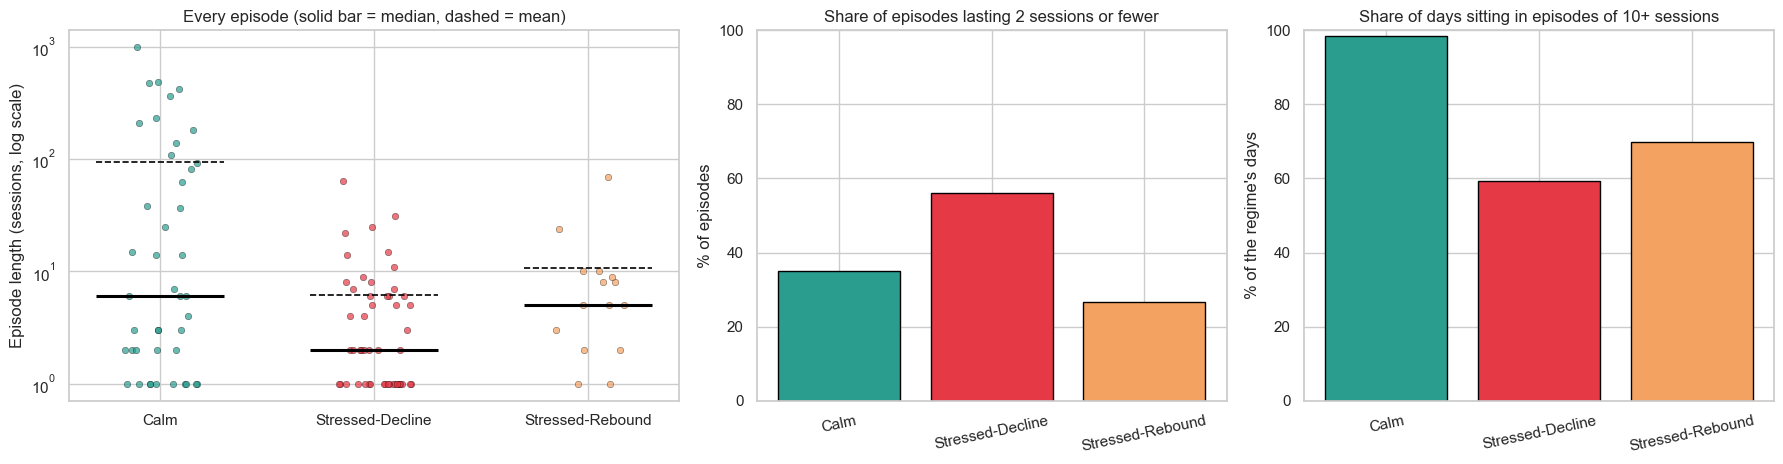

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for i, k in enumerate(REGIME_IDS):
    y = episodes.loc[episodes["regime"] == k, "sessions"].to_numpy()
    jitter = np.random.default_rng(SEED).uniform(-.18, .18, len(y))
    ax[0].scatter(np.full(len(y), i) + jitter, y, s=22, color=COLORS[k], alpha=.7, edgecolor="black", linewidth=.3, zorder=3)
    ax[0].hlines(np.median(y), i - .3, i + .3, color="black", lw=2.2, zorder=4)
    ax[0].hlines(np.mean(y), i - .3, i + .3, color="black", lw=1.2, ls="--", zorder=4)
ax[0].set_yscale("log"); ax[0].set_xticks(range(len(REGIME_IDS))); ax[0].set_xticklabels([REGIME_NAMES[k] for k in REGIME_IDS])
ax[0].set_ylabel("Episode length (sessions, log scale)"); ax[0].set_title("Every episode (solid bar = median, dashed = mean)")
dt = duration_table(episodes)
ax[1].bar([REGIME_NAMES[k] for k in REGIME_IDS], dt["Episodes <= 2 sessions (%)"], color=[COLORS[k] for k in REGIME_IDS], edgecolor="black")
ax[1].set_ylabel("% of episodes"); ax[1].set_title("Share of episodes lasting 2 sessions or fewer"); ax[1].set_ylim(0, 100)
ax[2].bar([REGIME_NAMES[k] for k in REGIME_IDS], dt["Regime days in episodes >= 10 sessions (%)"], color=[COLORS[k] for k in REGIME_IDS], edgecolor="black")
ax[2].set_ylabel("% of the regime's days"); ax[2].set_title("Share of days sitting in episodes of 10+ sessions"); ax[2].set_ylim(0, 100)
for a_ in ax[1:]:
    a_.tick_params(axis="x", rotation=12)
save_fig("duration")


**Interpretation of the durations**

| | Episodes | Mean | Median | Max | Episodes <= 2 sessions | Days in episodes of 10+ sessions |
|---|---|---|---|---|---|---|
| Calm | 43 | 94.0 | 6 | 990 | 35% | 98.5% |
| Stressed-Decline | 50 | 6.1 | 2 | 64 | 56% | 59.3% |
| Stressed-Rebound | 15 | 10.8 | 5 | 69 | 27% | 69.8% |

- **The mean alone would mislead for every regime.** Calm has a mean of 94 sessions but a median of 6: it consists of a few very long stretches (the longest, 990 sessions from 2016-02-15 to 2020-02-27, crosses the train/test boundary and so is one episode) and many short calm interludes inside crises. 98.5% of Calm days sit in episodes of 10 or more sessions, so most Calm *time* is long-lived, while a third of Calm *episodes* last two sessions or fewer.
- **Stressed-Decline is the least stable regime.** Median episode of 2 sessions, 56% of its 50 episodes last 2 sessions or fewer, and only 59% of its days are in episodes of 10 or more sessions. Its long episodes are the crisis runs (64 sessions in Sep-Dec 2008, 31 in Jun-Jul 2008, 25 in Mar-Apr 2020), and the rest is short flickering near the Calm boundary (August 2011, 2013 and 2015). This agrees with its weak silhouette in Phase 6 and with its low persistence in test. Phase 9 should expect many one- and two-day signals from this regime.
- **Stressed-Rebound** is fewer, longer and more concentrated: 15 episodes, median 5, longest 69 sessions (2009-03-23 to 2009-07-03), 70% of days in 10+ session episodes.
- **Partial episodes:** the first (Stressed-Decline, 31 sessions from 2008-06-09, left-cut) and the last (Calm, 139 sessions from 2026-04-07, right-cut) have unknown true lengths. Dropping them changes Calm to 42 episodes with mean 92.9 and Stressed-Decline to 49 episodes with mean 5.6; medians and conclusions do not change.
- **Caution on persistence:** the features use 10, 21 and 63-day rolling windows, so they cannot change quickly and some persistence is mechanical smoothing, not evidence that the market itself switches slowly. The flicker in Stressed-Decline occurs *despite* this smoothing, which shows that regime lies close to a cluster boundary.
- **Ranking by persistence:** Calm (daily staying probability 0.990), then Stressed-Rebound (0.907), then Stressed-Decline (0.837).


## 7. 7.4 Regime stability check (T2, optional)

> **Kept separate from the T1 results above.** The models in this section are *sensitivity analyses*. They do **not** replace the Phase 6 regimes, and `regimes.csv` is not modified.

**What:** refit the whole Phase 6 pipeline (StandardScaler, then PCA keeping the smallest number of components that reaches 85% variance, then K-Means with k = 3, `n_init = 50`, seed 42) on three different training windows, assign every date with the refitted model, and compare with the primary labels.

**Why this matters:** the scaler's mean and variance, the PCA axes and the K-Means centres are all estimated from the training window. A different window changes the *reference distribution*: what counts as "high" volatility depends on what volatility the model has seen. If the regimes were a stable feature of this market, a reasonable change of window should reproduce them. If they only exist because 2008-09 sits in the training data, the regimes are a property of the sample, and that is exactly what Phase 6 warned about.

**Windows (chosen before looking at results):**

| Window | Dates | What it tests |
|---|---|---|
| **A** | 2010-01-01 to 2019-12-31 | The post-crisis decade: **no 2008-09 crisis**, includes 2011, 2013, 2015, 2018. Do the regimes survive without the GFC? |
| **B** | 2008-06-09 to 2014-12-31 | **Shorter** (about 1,600 sessions) but includes the GFC. Does the structure depend on the training length? |
| **C** | 2013-01-01 to 2022-12-31 | A recent decade with **Covid but no GFC**. Can a different crisis anchor the stressed regimes? |

**Comparing cluster labels from independent fits.** Cluster IDs are arbitrary and can be permuted between fits, so we never compare label numbers directly. Instead:
- the **Adjusted Rand Index (ARI)** compares the two partitions without matching labels (1 = identical partition, about 0 = no better than chance);
- the **Hungarian-aligned agreement** first finds the one-to-one relabelling of the alternative regimes that maximises overlap with the primary ones, then reports the share of days with the same label;
- the **stressed-versus-calm agreement** collapses both to two groups, which is the coarsest question and the one the risk overlay depends on most.
We compare on (i) all dates (dates outside the alternative window are out-of-sample for the alternative model) and (ii) dates inside **both** training windows.
For readability, alternative regimes are also ordered by their mean VIX in their own training window (0 = lowest), the same convention as Phase 6.

**Limitations:** the windows overlap heavily with the primary one and with each other, so the comparisons are not independent; only three alternatives are tried; k is fixed at 3 for comparability (the best k for each window is reported separately); and ARI is sensitive to cluster sizes, so a few reassigned days in a small regime can move it a lot.

In [20]:
FEATURE_COLS = [c for c in features.columns if c != "split"]
ALT_WINDOWS = {"A 2010-2019 (no GFC)": ("2010-01-01", "2019-12-31"),
               "B 2008-2014 (shorter, with GFC)": ("2008-06-09", "2014-12-31"),
               "C 2013-2022 (Covid, no GFC)": ("2013-01-01", "2022-12-31")}

def fit_alt(start, end, k=3):
    tr = features.loc[start:end, FEATURE_COLS]
    sc = StandardScaler().fit(tr); Z = sc.transform(tr)                                  # window only
    cum = np.cumsum(PCA(random_state=SEED).fit(Z).explained_variance_ratio_)
    m = int(np.argmax(cum >= 0.85) + 1)                                                  # same rule as Phase 6
    pca_ = PCA(n_components=m, random_state=SEED).fit(Z); X = pca_.transform(Z)
    sil = {kk: float(silhouette_score(X, KMeans(kk, n_init=50, random_state=SEED).fit_predict(X))) for kk in range(2, 6)}
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    order = tr["vix_level"].groupby(km.labels_).mean().sort_values().index                # 0 = lowest mean VIX in the window
    relabel = {int(old): new for new, old in enumerate(order)}
    lab_all = pd.Series(km.predict(pca_.transform(sc.transform(features[FEATURE_COLS]))), index=features.index).map(relabel)
    return {"labels": lab_all, "n_train": len(tr), "components": m, "variance": float(pca_.explained_variance_ratio_.sum()), "sil": sil, "train_index": tr.index}

alt = {name: fit_alt(*win) for name, win in ALT_WINDOWS.items()}

def compare(primary, other, idx):
    ct = pd.crosstab(primary.loc[idx], other.loc[idx]).reindex(index=REGIME_IDS, columns=REGIME_IDS, fill_value=0)
    r, c = linear_sum_assignment(-ct.to_numpy())
    return {"ARI": float(adjusted_rand_score(primary.loc[idx], other.loc[idx])),
            "Hungarian-aligned agreement": float(ct.to_numpy()[r, c].sum() / ct.to_numpy().sum()),
            "Stressed vs calm agreement": float(((primary.loc[idx] > 0) == (other.loc[idx] > 0)).mean()), "crosstab": ct}

rows = []
for name, a in alt.items():
    overlap = reg.index.intersection(a["train_index"]).intersection(features.loc[:meta["train_end"]].index)
    c_all, c_ov = compare(reg, a["labels"], reg.index), compare(reg, a["labels"], overlap)
    best_k = max(a["sil"], key=a["sil"].get)
    rows.append({"Alternative window": name, "Train sessions": a["n_train"], "PCA components": a["components"], "Variance kept": round(a["variance"], 3),
                 "Silhouette k=2": round(a["sil"][2], 3), "Silhouette k=3": round(a["sil"][3], 3), "Silhouette k=4": round(a["sil"][4], 3),
                 "Best k by silhouette": best_k,
                 "ARI (all dates)": round(c_all["ARI"], 3), "ARI (dates in both training windows)": round(c_ov["ARI"], 3),
                 "Hungarian agreement (all dates)": round(c_all["Hungarian-aligned agreement"], 3),
                 "Stressed vs calm agreement (all dates)": round(c_all["Stressed vs calm agreement"], 3)})
stab = pd.DataFrame(rows).set_index("Alternative window")
print("Reference: Phase 6 silhouette for k = 2, 3, 4 =", {2: 0.493, 3: 0.456, 4: 0.234}, "(2008-2017 window)")
display(stab.astype(object).T)

  File "C:\Users\khush\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Reference: Phase 6 silhouette for k = 2, 3, 4 = {2: 0.493, 3: 0.456, 4: 0.234} (2008-2017 window)


Alternative window,A 2010-2019 (no GFC),"B 2008-2014 (shorter, with GFC)","C 2013-2022 (Covid, no GFC)"
Train sessions,2443,1600,2455
PCA components,11,8,10
Variance kept,0.873,0.853,0.859
Silhouette k=2,0.232,0.47,0.595
Silhouette k=3,0.178,0.477,0.204
Silhouette k=4,0.139,0.216,0.2
Best k by silhouette,2,3,2
ARI (all dates),0.119,0.747,0.15
ARI (dates in both training windows),0.05,0.744,0.067
Hungarian agreement (all dates),0.601,0.957,0.642


days  21d vol (ann.)  India VIX  drawdown  21d return
model                           regime (0 = lowest VIX)                                                       
PRIMARY (Phase 6, 2008-2017)    0                        4040           0.141     17.186    -0.068       0.012
                                1                         307           0.373     38.317    -0.322      -0.106
                                2                         162           0.409     41.854    -0.352       0.103
A 2010-2019 (no GFC)            0                        2275           0.110     14.552    -0.040       0.015
                                1                        1189           0.206     22.747    -0.119       0.049
                                2                        1045           0.244     26.625    -0.190      -0.057
B 2008-2014 (shorter, with GFC) 0                        4203           0.145     17.672    -0.073       0.009
                                1                         120           0.416     42.751    -0.351       0.111
                                2                         186           0.486     46.082    -0.435      -0.112
C 2013-2022 (Covid, no GFC)     0                        2730           0.131     16.400    -0.051       0.033
                                1                        1686           0.198     22.627    -0.148      -0.025
                                2                          93           0.616     54.344    -0.466      -0.177

A 2010-2019 (no GFC)


col_0,alt 0,alt 1,alt 2
regime,,,
primary Calm,2275,1058,707
primary Stressed-Decline,0,1,306
primary Stressed-Rebound,0,130,32


B 2008-2014 (shorter, with GFC)


col_0,alt 0,alt 1,alt 2
regime,,,
primary Calm,4040,0,0
primary Stressed-Decline,143,4,160
primary Stressed-Rebound,20,116,26


C 2013-2022 (Covid, no GFC)


col_0,alt 0,alt 1,alt 2
regime,,,
primary Calm,2676,1364,0
primary Stressed-Decline,0,217,90
primary Stressed-Rebound,54,105,3


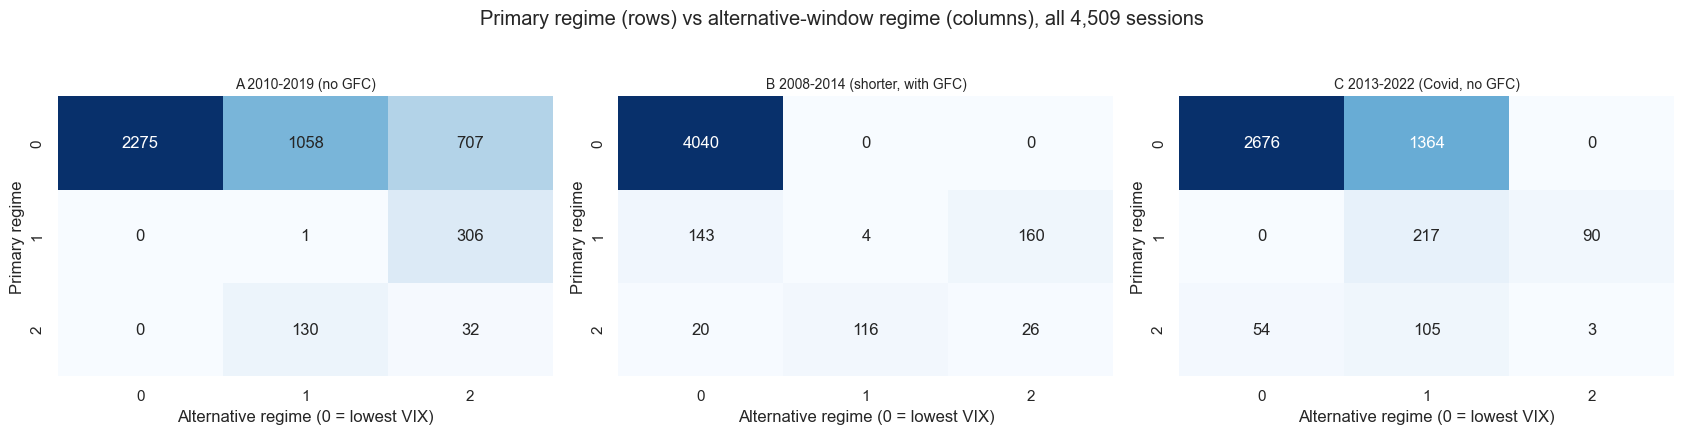

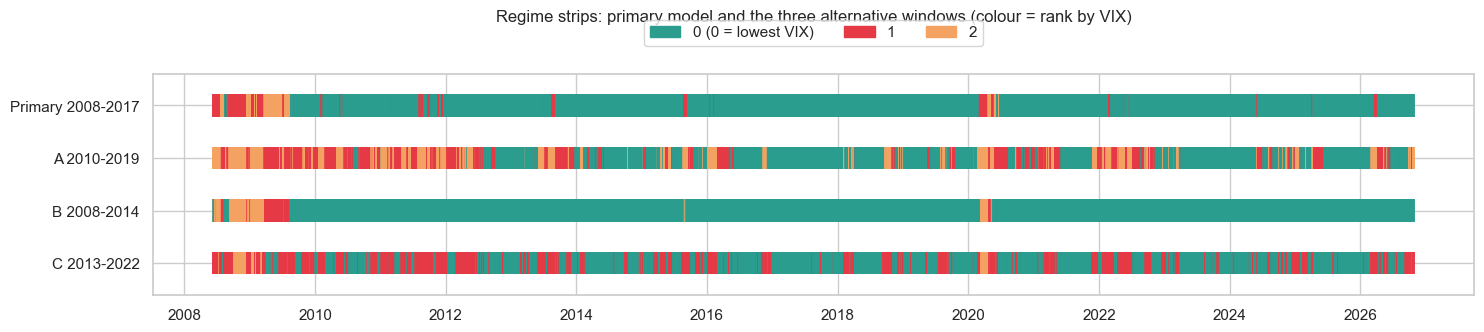

In [21]:
# Do the alternative regimes mean the same thing? Profile each alternative regime over ALL dates it is assigned to.
prof_cols = {"nifty_vol_21d": "21d vol (ann.)", "vix_level": "India VIX", "nifty_drawdown": "drawdown", "nifty_ret_21d": "21d return"}
def profile(labels):
    out = features[list(prof_cols)].groupby(labels).mean().rename(columns=prof_cols)
    out.insert(0, "days", labels.value_counts().sort_index())
    return out

blocks = {"PRIMARY (Phase 6, 2008-2017)": profile(reg)}
for name, a in alt.items():
    blocks[name] = profile(a["labels"])
display(pd.concat(blocks, names=["model", "regime (0 = lowest VIX)"]).round(3))

# raw contingency tables: primary regime (rows) vs alternative regime (columns, 0 = lowest VIX in that window)
for name, a_ in alt.items():
    print(name); display(compare(reg, a_["labels"], reg.index)["crosstab"].rename(index=lambda i: f"primary {REGIME_NAMES[i]}", columns=lambda j: f"alt {j}"))

# cross-tabs: primary (rows) vs alternative (columns)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a_, (name, a) in zip(ax, alt.items()):
    ct = compare(reg, a["labels"], reg.index)["crosstab"]
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a_)
    a_.set_xlabel("Alternative regime (0 = lowest VIX)"); a_.set_ylabel("Primary regime"); a_.set_title(name, fontsize=10)
fig.suptitle("Primary regime (rows) vs alternative-window regime (columns), all 4,509 sessions", y=1.03)
save_fig("stability_crosstabs")

# timeline strips
fig, ax = plt.subplots(figsize=(15, 3.6))
rows_ = [("Primary 2008-2017", reg)] + [(n.split(" ")[0] + " " + n.split(" ")[1], a["labels"]) for n, a in alt.items()]
for i, (n, s) in enumerate(rows_):
    ax.scatter(s.index, np.full(len(s), len(rows_) - 1 - i), c=[COLORS[v] for v in s], marker="|", s=260, linewidths=1.1)
ax.set_yticks(range(len(rows_))); ax.set_yticklabels([n for n, _ in rows_][::-1]); ax.set_ylim(-.6, len(rows_) - .4)
ax.legend(handles=[Patch(color=COLORS[k], label=f"{k} (0 = lowest VIX)" if k == 0 else str(k)) for k in REGIME_IDS], ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.28))
ax.set_title("Regime strips: primary model and the three alternative windows (colour = rank by VIX)", y=1.2)
save_fig("stability_timeline")

# save the sensitivity labels separately, never into regimes.csv
alt_out = pd.DataFrame({"regime_primary": reg})
for name, a in alt.items():
    alt_out["regime_alt_" + name.split(" ")[0]] = a["labels"]
alt_out.to_csv(PROC / "regime_stability_alt.csv", index_label="Date")
stab.to_csv(PROC / "regime_stability_summary.csv")


**Interpretation of the stability check (T2, sensitivity only)**

| Window | Silhouette k=2 / k=3 | Best k | ARI, all dates | Hungarian agreement | Stressed vs calm agreement |
|---|---|---|---|---|---|
| A 2010-2019 (no GFC) | 0.232 / 0.178 | 2 | 0.12 | 60% | 61% |
| B 2008-2014 (shorter, with GFC) | 0.470 / 0.477 | 3 | 0.75 | 96% | 96% |
| C 2013-2022 (Covid, no GFC) | 0.595 / 0.204 | 2 | 0.15 | 64% | 69% |

- **The regime structure is not robust to the training window; what matters is whether a deep crisis is in it.** B (a window 30% shorter but containing the 2008-09 crisis) reproduces the primary structure well: ARI 0.75, 96% of days agree after alignment, and its three regimes have the same profile type (calm, and two stressed regimes with VIX 43 and 46). Shortening the window is therefore not the problem.
- **Removing the GFC changes the result completely.** In window A, the best k is 2 and k = 3 has a silhouette of only 0.18 (Phase 6: 0.46). Its three regimes are a ladder of moderate volatility (mean VIX 14.6, 22.7, 26.6; drawdowns -4%, -12%, -19%). None of the primary stressed days are called Calm by A, so the stress ordering survives, but A labels 1,765 of the 4,040 primary Calm days (44%) as stressed. In other words, without 2008-09 in training, "stressed" means "somewhat above average", not crisis.
- **Window C shows the same thing with a different crisis.** With Covid in the window, one regime is a crisis cluster (93 sessions, VIX 54, volatility 62%, drawdown -47%), and 90 of its 93 days were Stressed-Decline in the primary model. But the middle regime (VIX 23) absorbs 1,364 days the primary model calls Calm. A deep crisis in training isolates a crisis cluster; how the rest of the data is split is not stable.
- **Even in B the Stressed-Decline boundary moves:** 143 of the 307 primary Stressed-Decline days (47%) are labelled Calm by B, and B's regime order by VIX is swapped (its higher-VIX stressed regime matches the primary Stressed-Decline). The structure is reproduced, but the edge between Calm and Stressed-Decline is soft.
- **What this means for the project:** (1) the Phase 6 regimes are defined *relative to the 2008-09 crisis* (VIX of roughly 38 to 43 is typical of the stressed regimes); (2) the frozen Phase 6 model is a legitimate fixed rule for Phases 8 and 9, but results are conditional on that training window; (3) any live "retrain on new data" step in the app would change the regime definitions and should not be added without re-validating; (4) the choice of k = 3 is supported only when a crisis is in the training data.
- **Limitations of this comparison:** only three alternative windows, all overlapping heavily with each other and the primary window; k fixed at 3 for comparability; ARI is sensitive to the size of small clusters; and the alternative models are **not** proposed as replacements: `regimes.csv` is unchanged.


## 8. Final validation summary

**Saved outputs** and the checks that guard them are in the next cell, followed by the answers to the eight validation questions.

In [22]:
# ---- save T1 tables ----
ev.drop(columns=["key"]).to_csv(PROC / "regime_event_validation.csv", index=False)
pd.concat({"all": stats_all, "train": stats_block(ret[split == "train"], reg[split == "train"], vix[split == "train"]),
           "test": stats_block(ret[split == "test"], reg[split == "test"], vix[split == "test"])}, names=["period"]).to_csv(PROC / "regime_statistics.csv")
indep_all.to_csv(PROC / "regime_independent_evidence.csv")
bench.to_csv(PROC / "regime_vs_vix_benchmark.csv")
pd.concat({"counts": named(M_all), "probabilities": named(P_all)}, names=["table"]).to_csv(PROC / "regime_transition_matrix.csv")
episodes.assign(regime_name=episodes["regime"].map(REGIME_NAMES)).to_csv(PROC / "regime_episodes.csv", index=False)
duration_table(episodes).to_csv(PROC / "regime_duration_summary.csv")

# ---- final checks ----
before = pd.read_csv(PROC / "regimes.csv", index_col="Date", parse_dates=True)
assert before["regime"].equals(reg) and before.shape == regimes.shape, "regimes.csv must be unchanged by Phase 7"
assert (episodes["sessions"].sum() == len(reg)) and np.allclose(P_all.sum(axis=1), 1)
assert ev[ev["role"] == "required"].shape[0] == 5
expected = ["regime_event_validation.csv", "regime_statistics.csv", "regime_independent_evidence.csv", "regime_vs_vix_benchmark.csv", "regime_transition_matrix.csv",
            "regime_episodes.csv", "regime_duration_summary.csv", "regime_stability_alt.csv", "regime_stability_summary.csv"]
assert all((PROC / f).exists() for f in expected)
print("Phase 6 regimes.csv is unchanged. Saved to data/processed/:")
for f in expected:
    print("  ", f)
print("Figures saved to reports/figures/ with prefix regime_val_:", sorted(p.name for p in FIG_DIR.glob("regime_val_*.png")))

Phase 6 regimes.csv is unchanged. Saved to data/processed/:
   regime_event_validation.csv
   regime_statistics.csv
   regime_independent_evidence.csv
   regime_vs_vix_benchmark.csv
   regime_transition_matrix.csv
   regime_episodes.csv
   regime_duration_summary.csv
   regime_stability_alt.csv
   regime_stability_summary.csv
Figures saved to reports/figures/ with prefix regime_val_: ['regime_val_boxplots.png', 'regime_val_duration.png', 'regime_val_event_distribution.png', 'regime_val_regime_stats_bootstrap.png', 'regime_val_stability_crosstabs.png', 'regime_val_stability_timeline.png', 'regime_val_timeline.png', 'regime_val_transition_heatmaps.png']



### Answers to the eight validation questions

**1. Do the discovered regimes correspond to recognisable historical market conditions?** Partly. The two severe episodes are recognised (2008: 79% Stressed-Decline, 21% Stressed-Rebound, 0% Calm; 2020 crash: 62% Stressed-Decline). The three milder episodes are mostly labelled Calm (2011: 57%, 2013: 87%, 2022: 86%), with stressed labels in their sharpest weeks. Quiet control years (2017, 2023) are 100% Calm. The labels also lag the market: they first fired after the Nifty had already fallen 5% to 8% in the four events where they were not already stressed.

**2. Are the regimes statistically distinguishable?** Calm versus stressed: yes, clearly. Same-day volatility is 14% against 38 to 45%, and, on variables that were not clustering inputs, forward 21-day volatility is 14% against 35 to 37% and next-day absolute return is about three times larger. Bootstrap intervals exclude zero and are not sensitive to block length. **The two stressed regimes are not distinguishable on volatility** (intervals include zero); they differ in direction and skewness.

**3. Does each regime have a meaningful return and volatility profile?** Yes, with caveats. Calm: low volatility, small positive mean. Stressed-Decline: negative mean, heaviest downside (30.6% of days below -2%, worst day -13.9%). Stressed-Rebound: positive mean, positive skew, high volatility. The return differences between regimes are partly built in because returns were clustering inputs.

**4. Which regimes show the highest persistence?** Calm (stays 99.0% of sessions per day, longest run 990 sessions), then Stressed-Rebound (90.7%, mean run 10.8) and Stressed-Decline (83.7%, mean 6.1 and median 2 sessions). Some persistence is mechanical, from the rolling-window features.

**5. Which transitions occur most frequently?** Calm to Stressed-Decline (39) and Stressed-Decline back to Calm (38) dominate, then Stressed-Decline to Stressed-Rebound (12) and Stressed-Rebound to Stressed-Decline (10). Calm jumps directly to Stressed-Rebound only 3 times.

**6. Do the results support the names assigned in Phase 6?** *Calm*: yes. *Stressed-Decline*: yes (negative returns, heavy downside). *Stressed-Rebound*: broadly (positive returns and skew while VIX is high) but less convincingly out-of-sample (42% in the 2020 rebound) and it cannot be separated from Stressed-Decline on volatility.

**7. Limitations of this validation:**
- the stressed regimes rest on two crises (2008-09 in training, 2020 in test) with 90 stressed test days;
- the same-day statistics are an internal consistency check, because those variables were clustering inputs;
- the regimes explain forward volatility no better than three VIX buckets of the same size, and a continuous VIX does better;
- the labels lag the market and mostly miss milder stress;
- Stressed-Decline flickers (median episode 2 sessions) and is the least stable regime;
- the regime definitions depend on 2008-09 being in the training window (7.4);
- event windows were chosen with hindsight and no ground truth exists;
- no formal significance tests were used, because daily data are autocorrelated and fat-tailed; the bootstrap intervals are probably still too narrow.

**8. Are the regimes meaningful enough to proceed to Phase 8?** **Yes, with specific cautions.** The Calm versus stressed distinction is real, forward-looking and survives out-of-sample, which is what the classifier and risk overlay need. But Phase 8 should (a) be judged on stressed-class recall and macro-F1, since the "tomorrow = today" baseline already scores 97.6% accuracy (98.2% in test); (b) report the stressed class counts (90 stressed test days, from essentially one episode); (c) include a plain VIX-threshold rule as a baseline, since the regimes add no forecasting power for volatility beyond VIX; and (d) consider whether the two stressed regimes should be merged for classification, which is a decision for Phase 8 and does not change `regimes.csv`. Phase 9 should expect detection lag, flicker from Stressed-Decline, and an average rebound after stress that a de-risking rule would forgo.

### Strengths and weaknesses at a glance

| Strengths | Weaknesses |
|---|---|
| Severe stress (2008, 2020) clearly recognised; quiet controls stay Calm | Milder stress (2011, 2013, 2022) mostly labelled Calm |
| Calm vs stressed differ strongly on forward volatility, in and out of sample | No forecasting power beyond a size-matched VIX rule |
| Persistent regimes; Calm and Rebound have sensible durations | Stressed-Decline flickers; stressed persistence is lower in test |
| Names supported by the statistical profiles | Stressed regimes not separable on volatility; Rebound weaker out-of-sample |
| Structure reproduced when a deep crisis is in the training window | Definitions depend on 2008-09 being in training |
